# Kalman forward correction + RUDDER — standalone Colab notebook

**No external files. Standard scientific imports only.** All simulator, filter, policy and RUDDER definitions are written directly into the code cells. The measured EELS arrays and nine fitted models' numeric parameters are embedded inside this `.ipynb`; no repository, Drive mount, custom module, data download or checkpoint file is needed.

**Runtime → Run all** repeats the evaluation by executing **720 fresh simulated campaigns** and regenerating the figures from those new outputs. It does not read saved metric tables or figure files. The embedded parameters come from the completed 384-campaign-per-controller pilot described below. To retrain instead, set `RUN_TRAINING=True`; the full training procedure is also inline and uses in-memory data.

Choose a standard **CPU** Colab runtime. The main scientific packages are NumPy, SciPy, scikit-learn, PyTorch, pandas and Matplotlib. Evaluation runs sequentially for notebook portability. Execution time depends on the assigned CPU and package versions. The original pilot's exact versions are printed below; different library versions can change numerical results.

## What is being learned?

The policy chooses **IMAGE at one of eight acquisition settings**, **CALIBRATE**, or **SPECTRUM**. The Kalman filter determines the beam correction at the spectrum midpoint. RUDDER predicts the user-defined terminal return and redistributes credit to earlier commands; it does not define scientific success.

The scientific predictor remains the original random forest mapping image features to five measured spectral principal components. The return remains $G=U_0-U_T$, the decrease of its ensemble disagreement on an unlabeled reference set. Held-out spectral MSE and physical registration error are separate audit measures.

Spatial target order is randomized in advance. Target selection itself is not learned in this version.

In [1]:
#@title Standard imports and experiment controls
import os, sys, io, base64, hashlib, zlib, json, copy, time, unittest
from dataclasses import dataclass, field, asdict, replace
from pathlib import Path
from typing import Any, Callable, Iterable, Sequence
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
import numpy as np
import scipy
from scipy.ndimage import gaussian_filter1d, map_coordinates
from scipy.spatial import cKDTree
import sklearn
from sklearn.ensemble import RandomForestRegressor
import torch
from torch import nn
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
torch.set_num_threads(1)

# Evaluation repeats the full pilot test set by default.
RUN_TRAINING = False
EVALUATION_SEEDS_PER_REGIME = 20
EVALUATION_FIRST_SEED = 950000
TRAINING_EPISODES = 384
WARMUP_EPISODES = 64
POLICY_BATCH_SIZE = 8
TRAINING_SEEDS = [0, 1, 2]
COST_RANDOMIZATION = False

print("Current versions:", {"python":sys.version.split()[0], "numpy":np.__version__,
      "scipy":scipy.__version__, "scikit-learn":sklearn.__version__, "torch":torch.__version__})


Current versions: {'python': '3.12.14', 'numpy': '2.3.5', 'scipy': '1.17.0', 'scikit-learn': '1.8.0', 'torch': '2.15.0+cpu'}


## 1. Scientific learner and physical environment

The following cell contains the full base simulator and random-forest learner. It uses measured image/spectral arrays defined later in this notebook. No function in this notebook reads a dataset or project file.

In [2]:
#@title Full scientific learner and base environment
"""Budgeted microscopy with real EELS measurements and simulated drift/blur.

Policy input is ``observation()`` only. True drift, physical positions, nearest
pixel errors and hidden test labels occur only in simulator/audit objects.
Calibration is an ideal reactive registration measurement at its completion:
it returns the beam to the material anchor of the cached image and leaves that
image intact. No future drift prediction or Kalman filter is present.

Finite-field limitation: image patches use reflected padding, matching the
source notebook, while spectroscopy chooses the nearest eligible measured
pixel only for centers inside the measured field. An outside-field spectroscopy
attempt consumes time but produces no supervised pair. Those failure rates and
nearest-pixel distances are explicitly audited.
"""
from __future__ import annotations
from dataclasses import dataclass, field
import hashlib
import json
from pathlib import Path
from typing import Any
import numpy as np
from scipy.ndimage import gaussian_filter1d, map_coordinates
from scipy.spatial import cKDTree
from sklearn.ensemble import RandomForestRegressor
IMAGE_ACTIONS = tuple(range(8))
CALIBRATE = 8
SPECTRUM = 9
N_ACTIONS = 10
PATCH_SIZE = 17
POOL_SIZE = 7
_GRID_R, _GRID_C = np.meshgrid(np.arange(-8, 9), np.arange(-8, 9), indexing='ij')
_POOL_WEIGHTS = np.zeros((POOL_SIZE, PATCH_SIZE), np.float32)
for _i in range(POOL_SIZE):
    _start, _end = (int(np.floor(_i * PATCH_SIZE / POOL_SIZE)), int(np.ceil((_i + 1) * PATCH_SIZE / POOL_SIZE)))
    _POOL_WEIGHTS[_i, _start:_end] = 1.0 / (_end - _start)

@dataclass(frozen=True)
class BaseConfig:
    budget: float = 65.0
    taus: tuple[float, ...] = tuple((float(x) for x in np.linspace(0.2, 1.0, 8)))
    image_cost_factor: float = 3.0
    cal_cost: float = 1.0
    spectrum_duration: float = 1.0
    survey_cost: float = 5.0
    seed_tau: float = 0.8
    seed_pairs: int = 4
    ref_size: int = 64
    rf_trees: int = 24
    rf_min_samples_leaf: int = 2
    rf_max_features: float = 0.8
    rf_seed: int = 42
    max_images_per_target: int | None = None
    velocity: float = 0.4
    drift_period: float = 48.0
    random_walk_scale: float = 0.16
    periodic_amplitude: float = 3.0
    regimes: tuple[str, ...] = ('random', 'linear', 'periodic')

    def __post_init__(self) -> None:
        if len(self.taus) != 8 or any((not 0 < x <= 1 for x in self.taus)):
            raise ValueError('Exactly eight positive acquisition fractions <=1 are required.')
        if min(self.budget, self.image_cost_factor, self.cal_cost, self.spectrum_duration) <= 0:
            raise ValueError('Budget and acquisition durations must be positive.')
        if self.seed_pairs < 4 or self.ref_size < 1 or self.rf_trees < 2:
            raise ValueError('Insufficient initialization/model size or invalid image limit.')
        if self.max_images_per_target is not None and self.max_images_per_target < 1:
            raise ValueError('Optional image limit must be positive.')

def blur_sigma(tau: float) -> float:
    return float(np.sqrt(max(0.0, (1.0 / float(tau) - 1.0) / 0.12)))

def pool_features(patches: np.ndarray) -> np.ndarray:
    """Equivalent to a 17x17 -> 7x7 adaptive average pool; no Torch dependency."""
    arr = np.asarray(patches, dtype=np.float32)
    if arr.ndim == 2:
        arr = arr[None]
    if arr.shape[-2:] != (PATCH_SIZE, PATCH_SIZE):
        raise ValueError('Expected one or more 17x17 structural patches.')
    pooled = np.matmul(_POOL_WEIGHTS, np.matmul(arr, _POOL_WEIGHTS.T))
    return pooled.reshape(len(arr), -1)

@dataclass
class DataBundle:
    image: np.ndarray
    pool_ids: np.ndarray
    seed_ids: np.ndarray
    ref_ids: np.ndarray
    test_ids: np.ndarray
    pool_targets: np.ndarray
    seed_targets: np.ndarray
    hidden_test_targets: np.ndarray
    metadata: dict[str, Any]
    centers: np.ndarray = field(init=False)
    pool_tree: cKDTree = field(init=False, repr=False)
    image_mean: float = field(init=False)
    image_std: float = field(init=False)
    _feature_cache: dict = field(default_factory=dict, init=False, repr=False)

    def __post_init__(self) -> None:
        h, w = self.image.shape
        self.centers = np.stack(np.unravel_index(np.arange(h * w), (h, w)), axis=1).astype(np.float64)
        self.pool_tree = cKDTree(self.centers[self.pool_ids])
        self.image_mean = float(self.image.mean())
        self.image_std = max(float(self.image.std()), 1e-08)
        groups = [self.pool_ids, self.seed_ids, self.ref_ids, self.test_ids]
        for i, left in enumerate(groups):
            for right in groups[i + 1:]:
                if np.intersect1d(left, right).size:
                    raise ValueError('Learning/reference/test partitions overlap.')
        if self.pool_targets.shape != (len(self.pool_ids), 5) or self.seed_targets.shape != (len(self.seed_ids), 5):
            raise ValueError('Measured target shape mismatch.')
        if self.hidden_test_targets.shape != (len(self.test_ids), 5):
            raise ValueError('Hidden test target shape mismatch.')

    def crop(self, position: np.ndarray, tau: float=1.0) -> np.ndarray:
        row, col = np.asarray(position, dtype=float)
        patch = map_coordinates(self.image, [row + _GRID_R, col + _GRID_C], order=1, mode='reflect')
        sigma = blur_sigma(tau)
        if sigma > 1e-08:
            patch = gaussian_filter1d(patch, sigma, axis=1, mode='reflect')
        return patch.astype(np.float32)

    def fixed_features(self, ids: np.ndarray, tau: float=1.0) -> np.ndarray:
        ids = np.asarray(ids, dtype=np.int64)
        key = (ids.tobytes(), float(tau))
        if key not in self._feature_cache:
            self._feature_cache[key] = pool_features(np.stack([self.crop(self.centers[i], tau) for i in ids]))
        return self._feature_cache[key]

class DriftWorld:
    """Continuous queryable latent trajectory, fixed for a complete campaign."""

    def __init__(self, regime: str, seed: int, cfg: BaseConfig):
        if regime not in {'random', 'linear', 'periodic'}:
            raise ValueError(f'Unknown drift regime {regime!r}')
        self.regime, self.seed, self.cfg = (regime, int(seed), cfg)
        rng = np.random.default_rng(seed)
        angle = rng.uniform(0, 2 * np.pi)
        self.velocity = cfg.velocity * np.array([np.cos(angle), np.sin(angle)])
        self.phase = rng.uniform(0, 2 * np.pi)
        count = max(2000, int(np.ceil(cfg.budget)) + 4)
        increments = np.random.default_rng(seed + 100000).normal(scale=cfg.random_walk_scale, size=(count, 2))
        self.knots = np.vstack([np.zeros((1, 2)), np.cumsum(increments, axis=0)])

    def true(self, time: float) -> np.ndarray:
        time = max(0.0, float(time))
        index = min(int(time), len(self.knots) - 2)
        fraction = time - index
        random_walk = (1 - fraction) * self.knots[index] + fraction * self.knots[index + 1]
        if self.regime == 'random':
            return random_walk
        linear = self.velocity * time + 0.18 * random_walk
        if self.regime == 'linear':
            return linear
        theta = 2 * np.pi * time / self.cfg.drift_period + self.phase
        periodic = np.array([np.sin(theta) - np.sin(self.phase), np.cos(theta) - np.cos(self.phase)])
        return linear + self.cfg.periodic_amplitude * periodic

class ScienceLearner:
    """Same RF and target representation for every controller/reward method."""

    def __init__(self, data: DataBundle, cfg: BaseConfig, initial_indices: np.ndarray):
        self.data, self.cfg = (data, cfg)
        self.initial_ids = data.seed_ids[initial_indices].copy()
        self.train_features = [row.copy() for row in data.fixed_features(self.initial_ids, cfg.seed_tau)]
        self.train_targets = [row.copy() for row in data.seed_targets[initial_indices]]
        self.measured_ids = [int(x) for x in self.initial_ids]
        self.reference_ids = data.ref_ids[:min(cfg.ref_size, len(data.ref_ids))].copy()
        self.reference_features = data.fixed_features(self.reference_ids, 1.0)
        self.n_updates = 0
        self.refit()

    def refit(self) -> None:
        self.model = RandomForestRegressor(n_estimators=self.cfg.rf_trees, min_samples_leaf=self.cfg.rf_min_samples_leaf, max_features=self.cfg.rf_max_features, n_jobs=1, random_state=self.cfg.rf_seed)
        self.model.fit(np.stack(self.train_features), np.stack(self.train_targets))
        individual = np.stack([tree.predict(self.reference_features) for tree in self.model.estimators_])
        self.current_U = float(individual.var(axis=0, ddof=0).mean())

    def append(self, patch: np.ndarray, pool_index: int) -> float:
        old_u = self.current_U
        self.train_features.append(pool_features(patch)[0])
        self.train_targets.append(self.data.pool_targets[pool_index].copy())
        self.measured_ids.append(int(self.data.pool_ids[pool_index]))
        self.n_updates += 1
        self.refit()
        return float(old_u - self.current_U)

    def hidden_test_mse(self) -> float:
        features = self.data.fixed_features(self.data.test_ids, 1.0)
        prediction = self.model.predict(features)
        return float(np.mean((prediction - self.data.hidden_test_targets) ** 2))

class BaseCampaignEnv:
    """One episode is one complete paid campaign; actions 0..7 IMAGE,8 CAL,9 SPEC."""
    obs_names = ('time_remaining', 'has_cached_image', 'image_calibrated', 'last_tau', 'image_age', 'successful_pairs_fraction', 'images_fraction', 'calibrations_fraction', 'relative_uncertainty', 'last_calibration_age', 'last_measured_shift_row', 'last_measured_shift_col', 'commanded_correction_row', 'commanded_correction_col', 'images_this_target', 'time_since_spectrum', 'image_gradient', 'image_contrast', 'initial_uncertainty', 'current_uncertainty') + tuple((f'image_pool_{i}' for i in range(49)))

    def __init__(self, data: DataBundle, cfg: BaseConfig | None=None, seed: int=0, regime: str | None=None):
        self.data, self.cfg, self.seed = (data, cfg or BaseConfig(), int(seed))
        self.regime = regime or self.cfg.regimes[self.seed % len(self.cfg.regimes)]
        self.reset()

    def reset(self) -> np.ndarray:
        cfg = self.cfg
        self.world = DriftWorld(self.regime, self.seed + 1500, cfg)
        self.target_order = np.random.default_rng(self.seed + 700).permutation(self.data.pool_ids)
        self.cursor = 0
        self.target_id = int(self.target_order[0])
        initial_indices = np.random.default_rng(self.seed + 900).choice(len(self.data.seed_ids), size=min(cfg.seed_pairs, len(self.data.seed_ids)), replace=False)
        self.science = ScienceLearner(self.data, cfg, initial_indices)
        self.initial_cost = cfg.survey_cost + len(initial_indices) * (cfg.image_cost_factor * cfg.seed_tau + cfg.spectrum_duration)
        self.t = float(self.initial_cost)
        if self.t + cfg.image_cost_factor * min(cfg.taus) + cfg.spectrum_duration > cfg.budget:
            raise ValueError('Budget cannot cover the common survey, registered seed pairs, and one measurement.')
        self.U0 = float(self.science.current_U)
        self.correction = self.world.true(self.t).copy()
        self.last_measured_shift = self.correction.copy()
        self.last_calibration_time = self.t
        self.initial_heldout_mse = self.science.hidden_test_mse()
        self.last_spectrum_time = self.t
        self.cached_image = None
        self.cached_anchor = None
        self.last_tau = None
        self.image_midpoint = None
        self.calibrated = False
        self.images_this_target = 0
        self.counts = {'image': 0, 'calibrate': 0, 'spectrum': 0, 'successful_pairs': 0, 'failed_spectra': 0}
        self.image_action_counts = np.zeros(8, dtype=int)
        self.trace: list[dict[str, Any]] = []
        self.spec_trace: list[dict[str, Any]] = []
        self.done = False
        return self.observation()

    @property
    def terminal_score(self) -> float:
        return float(self.U0 - self.science.current_U)

    @property
    def Ufinal(self) -> float:
        return float(self.science.current_U)

    def action_mask(self) -> np.ndarray:
        mask = np.zeros(N_ACTIONS, dtype=bool)
        if self.done:
            return mask
        cfg = self.cfg
        if cfg.max_images_per_target is None or self.images_this_target < cfg.max_images_per_target:
            mask[:8] = self.t + cfg.image_cost_factor * np.asarray(cfg.taus) + cfg.spectrum_duration <= cfg.budget + 1e-09
        if self.cached_image is not None:
            mask[CALIBRATE] = self.t + cfg.cal_cost + cfg.spectrum_duration <= cfg.budget + 1e-09
            mask[SPECTRUM] = self.t + cfg.spectrum_duration <= cfg.budget + 1e-09
        return mask

    def observation(self) -> np.ndarray:
        cfg = self.cfg
        cached = self.cached_image is not None
        if cached:
            normalized = (self.cached_image - self.data.image_mean) / self.data.image_std
            feature = pool_features(normalized)[0]
            gradient = float(np.mean(np.abs(np.diff(normalized, axis=1))))
            contrast = float(normalized.std())
        else:
            feature = np.zeros(49, dtype=np.float32)
            gradient = contrast = 0.0
        cal_age = 1.0 if self.last_calibration_time is None else (self.t - self.last_calibration_time) / cfg.budget
        scalar = [max(0.0, (cfg.budget - self.t) / cfg.budget), float(cached), float(self.calibrated), float(self.last_tau or 0.0), (self.t - self.image_midpoint) / cfg.budget if cached else 0.0, self.counts['successful_pairs'] / cfg.budget, self.counts['image'] / cfg.budget, self.counts['calibrate'] / cfg.budget, min(10.0, self.science.current_U / max(self.U0, 1e-06)), cal_age, *self.last_measured_shift / PATCH_SIZE, *self.correction / PATCH_SIZE, min(1.0, self.images_this_target / (cfg.budget / (cfg.image_cost_factor * min(cfg.taus)))), (self.t - self.last_spectrum_time) / cfg.budget, gradient, contrast, self.U0, self.science.current_U]
        result = np.concatenate([np.asarray(scalar, np.float32), feature]).astype(np.float32)
        if result.shape != (len(BaseCampaignEnv.obs_names),) or not np.isfinite(result).all():
            raise RuntimeError('Invalid policy observation.')
        return result

    def step(self, action: int) -> tuple[np.ndarray, float, bool, dict[str, Any]]:
        action = int(action)
        if not 0 <= action < N_ACTIONS or not self.action_mask()[action]:
            raise ValueError(f'Illegal action {action} at time {self.t:.6f}')
        cfg, start = (self.cfg, self.t)
        target_id = self.target_id
        target = self.data.centers[target_id]
        old_u = self.science.current_U
        event: dict[str, Any] = {'step': len(self.trace), 'action': action, 'time_start': float(start), 'target_id': int(target_id), 'U_before': float(old_u)}
        if action in IMAGE_ACTIONS:
            tau = cfg.taus[action]
            duration = cfg.image_cost_factor * tau
            midpoint = start + duration / 2
            position = target + self.world.true(midpoint) - self.correction
            self.cached_image = self.data.crop(position, tau)
            self.cached_anchor = position.copy()
            self.image_midpoint = midpoint
            self.last_tau = tau
            self.calibrated = False
            self.images_this_target += 1
            self.counts['image'] += 1
            self.image_action_counts[action] += 1
            self.t = start + duration
            h, w = self.data.image.shape
            outside = bool(position[0] < 0 or position[0] > h - 1 or position[1] < 0 or (position[1] > w - 1))
            padded = bool(position[0] < 8 or position[0] > h - 9 or position[1] < 8 or (position[1] > w - 9))
            event.update(kind='IMAGE', tau=float(tau), blur_sigma=blur_sigma(tau), sample_time=float(midpoint), image_midpoint=float(midpoint), actual_position=position.tolist(), image_anchor=position.tolist(), outside_source_field=outside, patch_uses_reflected_padding=padded)
        elif action == CALIBRATE:
            duration = cfg.cal_cost
            self.t = start + duration
            previous = self.correction.copy()
            self.correction = target + self.world.true(self.t) - self.cached_anchor
            self.last_measured_shift = self.correction - previous
            self.last_calibration_time = self.t
            self.calibrated = True
            self.counts['calibrate'] += 1
            event.update(kind='CALIBRATE', measured_shift=self.last_measured_shift.tolist(), correction=self.correction.tolist(), sample_time=float(self.t), actual_position=(target + self.world.true(self.t) - self.correction).tolist(), image_anchor=self.cached_anchor.tolist())
        else:
            duration = cfg.spectrum_duration
            midpoint = start + duration / 2
            position = target + self.world.true(midpoint) - self.correction
            self.t = start + duration
            h, w = self.data.image.shape
            outside = bool(position[0] < 0 or position[0] > h - 1 or position[1] < 0 or (position[1] > w - 1))
            quantization = real_id = source_position = measured_mismatch = None
            if not outside:
                quantization, pool_index = self.data.pool_tree.query(position)
                pool_index = int(pool_index)
                real_id = int(self.data.pool_ids[pool_index])
                source_position = self.data.centers[real_id].tolist()
                measured_mismatch = float(np.linalg.norm(self.data.centers[real_id] - self.cached_anchor))
                self.science.append(self.cached_image, pool_index)
                self.counts['successful_pairs'] += 1
            else:
                self.counts['failed_spectra'] += 1
            record = {'time': float(self.t), 'target_id': int(target_id), 'real_id': real_id, 'sample_time': float(midpoint), 'actual_position': position.tolist(), 'spectrum_midpoint': float(midpoint), 'spectrum_position': position.tolist(), 'source_id': real_id, 'source_position': source_position, 'image_anchor': self.cached_anchor.tolist(), 'image_midpoint': float(self.image_midpoint), 'pair_mismatch': float(np.linalg.norm(position - self.cached_anchor)), 'measured_pair_mismatch': measured_mismatch, 'absolute_target_error': float(np.linalg.norm(position - target)), 'nearest_spectrum_distance': float(quantization) if quantization is not None else None, 'quantization_error': float(quantization) if quantization is not None else None, 'outside_source_field': outside, 'successful_pair': not outside, 'acquisition_failed': outside, 'no_pair': outside, 'calibrated': bool(self.calibrated), 'tau': float(self.last_tau), 'n_images': int(self.images_this_target), 'U': self.science.current_U}
            self.spec_trace.append(record)
            event.update(kind='SPECTRUM', **{k: v for k, v in record.items() if k != 'target_id'})
            self.counts['spectrum'] += 1
            self.last_spectrum_time = self.t
            self.cursor += 1
            if self.cursor >= len(self.target_order):
                self.done = True
            else:
                self.target_id = int(self.target_order[self.cursor])
            self.cached_image = self.cached_anchor = None
            self.last_tau = self.image_midpoint = None
            self.calibrated = False
            self.images_this_target = 0
        if not self.action_mask().any():
            self.done = True
        if self.done:
            self.science.refit()
        reward = float(old_u - self.science.current_U)
        event.update(time_end=float(self.t), duration=float(duration), delta_U=reward, U_after=self.science.current_U, terminal=self.done)
        self.trace.append(event)
        if self.t > cfg.budget + 1e-08:
            raise RuntimeError('Campaign exceeded its experimental time budget.')
        info = {'action_name': event['kind'], 'duration': float(duration), 'delta_U': reward, 'time_used': self.t, 'terminal_score': self.terminal_score if self.done else None, 'audit': event.copy()}
        return (self.observation(), reward, self.done, info)

    def metrics(self) -> dict[str, Any]:

        def average(key: str) -> float:
            values = [x[key] for x in self.spec_trace if x[key] is not None]
            return float(np.mean(values)) if values else float('nan')
        images = [event for event in self.trace if event['kind'] == 'IMAGE']
        return {'seed': self.seed, 'regime': self.regime, 'budget': self.cfg.budget, 'time_used': float(self.t), 'initial_cost': float(self.initial_cost), 'U0': self.U0, 'Ufinal': self.Ufinal, 'terminal_score': self.terminal_score, 'heldout_mse': self.science.hidden_test_mse(), 'initial_heldout_mse': self.initial_heldout_mse, 'n_images': self.counts['image'], 'n_calibrations': self.counts['calibrate'], 'n_spectra': self.counts['spectrum'], 'n_seed_pairs': len(self.science.initial_ids), 'n_successful_pairs': self.counts['successful_pairs'], 'n_failed_spectra': self.counts['failed_spectra'], 'n_reference': len(self.science.reference_ids), 'counts': self.counts.copy(), 'image_action_counts': self.image_action_counts.tolist(), 'mean_pair_mismatch': average('pair_mismatch'), 'mean_measured_pair_mismatch': average('measured_pair_mismatch'), 'mean_absolute_target_error': average('absolute_target_error'), 'mean_nearest_spectrum_distance': average('nearest_spectrum_distance'), 'fraction_spectra_outside_source_field': average('outside_source_field'), 'fraction_images_outside_source_field': float(np.mean([x['outside_source_field'] for x in images])) if images else 0.0, 'fraction_image_patches_using_reflected_padding': float(np.mean([x['patch_uses_reflected_padding'] for x in images])) if images else 0.0, 'boundary_model': 'reflected image patches; outside-field SPEC costs time and yields no pair; in-field SPEC uses nearest eligible measured spectrum', 'setup_registration': 'common paid survey registers the initial map at t=initial_cost; drift clock is not reset', 'unique_acquired_spectra': len({x['real_id'] for x in self.spec_trace if x['real_id'] is not None})}

## 2. Kalman state, observations and spectrum correction

The state is $x=[c^*_{\rm row},c^*_{\rm col},v_{\rm row},v_{\rm col}]^T$, where $c^*(t)$ is the correction needed to revisit the current image's material anchor. If the image was acquired at midpoint $t_I$ using known correction $c_I$, then

$$c^*(t)=c_I+d(t)-d(t_I).$$

Only the physical simulator knows the true drift $d$. The filter observes a noisy image-relative registration shift **only when CALIBRATE completes**. A new IMAGE defines a new relative reference at its midpoint; it retains velocity and its covariance, and supplies no velocity observation. The spectrum correction is the predicted mean at $t_s+T_s/2$.

$$F(\Delta)=\begin{bmatrix}I&\Delta I\\0&I\end{bmatrix},\qquad
Q(\Delta)=\begin{bmatrix}(q_p\Delta+q_a\Delta^3/3)I&q_a\Delta^2I/2\\q_a\Delta^2I/2&q_a\Delta I\end{bmatrix}.$$

Calibration observes $z=c_{\rm applied}+\text{measured registration shift}$ with $H=[I\;0]$. Both reactive and Kalman modes immediately apply the same noisy calibration measurement. Only Kalman mode changes the subsequent spectrum command to the midpoint forecast. The measurement update uses the Joseph covariance formula.

The starting sensor SD is 0.10 pixels/axis; $q_p=0.0256$ pixels²/time, $q_a=0.0025$ pixels²/time³, and the initial velocity SD is 0.40 pixels/time/axis. These are proposed simulation assumptions, not calibrated instrument parameters.

In [3]:
#@title Full causal Kalman filter
"""Causal Kalman estimation of the correction needed for a cached image.

The state is [required_correction_row, required_correction_col,
              drift_velocity_row, drift_velocity_col].
Its position component is NOT an estimate supplied with absolute drift or the
cached image's true material coordinates. At an image's midpoint the required
correction is, by definition, the known correction used to acquire that image.
Reanchoring there sets the position covariance and position/velocity cross
covariance to zero, while retaining the propagated velocity belief.

A registration sensor reports image/beam mismatch m. Its observable measurement
is z = currently_applied_correction + m. Only this z, its observation time and
measurement covariance enter observe(). Future spectrum commands come from the
nonmutating forecast(spectrum_midpoint), never from simulator truth.
"""
from __future__ import annotations
from dataclasses import dataclass
from typing import Any
import numpy as np

@dataclass(frozen=True)
class KalmanConfig:
    """Continuous process noise parameters in the simulator's physical units.

    q_position: direct position diffusion, pixels**2 / time.
    q_acceleration: white acceleration spectral density, pixels**2 / time**3.
    initial_velocity_std: per-axis prior standard deviation, pixels / time.
    """
    q_position: float = 0.0256
    q_acceleration: float = 0.0025
    initial_velocity_std: float = 0.4

    def __post_init__(self) -> None:
        for name in ('q_position', 'q_acceleration', 'initial_velocity_std'):
            value = float(getattr(self, name))
            if not np.isfinite(value) or value < 0:
                raise ValueError(f'{name} must be finite and nonnegative')

def _vector(value, size: int, name: str) -> np.ndarray:
    result = np.asarray(value, dtype=np.float64)
    if result.shape != (size,) or not np.isfinite(result).all():
        raise ValueError(f'{name} must be a finite vector of length {size}')
    return result.copy()

def _covariance(value, size: int, name: str) -> np.ndarray:
    result = np.asarray(value, dtype=np.float64)
    if result.shape != (size, size) or not np.isfinite(result).all():
        raise ValueError(f'{name} must be a finite {size}x{size} covariance')
    scale = max(1.0, float(np.max(np.abs(result))))
    if not np.allclose(result, result.T, rtol=1e-10, atol=1e-12 * scale):
        raise ValueError(f'{name} must be symmetric')
    result = (result + result.T) / 2
    eigenvalues = np.linalg.eigvalsh(result)
    if eigenvalues[0] < -1e-10 * scale:
        raise ValueError(f'{name} is not positive semidefinite')
    if eigenvalues[0] < 0:
        eigenvalues, eigenvectors = np.linalg.eigh(result)
        result = eigenvectors * np.maximum(eigenvalues, 0) @ eigenvectors.T
        result = (result + result.T) / 2
    return result.copy()

def transition_matrices(dt: float, q_position: float=0.0256, q_acceleration: float=0.0025) -> tuple[np.ndarray, np.ndarray]:
    """Exact discretization of position diffusion plus white acceleration.

    F = [[I, dt I], [0, I]]
    Q = [[(q_p dt + q_a dt**3/3) I, q_a dt**2/2 I],
         [q_a dt**2/2 I,                 q_a dt I]].
    """
    dt, qp, qa = (float(dt), float(q_position), float(q_acceleration))
    if not np.isfinite([dt, qp, qa]).all() or min(dt, qp, qa) < 0:
        raise ValueError('Time increments and process densities must be finite and nonnegative')
    eye = np.eye(2)
    F = np.eye(4)
    F[:2, 2:] = dt * eye
    Q = np.zeros((4, 4))
    Q[:2, :2] = (qp * dt + qa * dt ** 3 / 3) * eye
    Q[:2, 2:] = qa * dt ** 2 / 2 * eye
    Q[2:, :2] = Q[:2, 2:]
    Q[2:, 2:] = qa * dt * eye
    return (F, Q)

class KalmanDriftFilter:
    """Small, independent filter with absolute timestamps and causal updates.

    Constructor position is a known correction in the current reference frame.
    The default covariance treats it as known and supplies uncertainty only in
    velocity. An IMAGE action must call reanchor(applied_correction, midpoint)
    before propagating to its completion. No delayed observations are silently
    accepted; callers must process IMAGE midpoint/reference changes in order.

    Public x/P/time are convenient for the simulator, while all returned arrays
    are copies. forecast(time) never advances the stored posterior.
    """

    def __init__(self, position=None, velocity=None, *, time: float=0.0, covariance=None, config: KalmanConfig | None=None) -> None:
        self.config = config or KalmanConfig()
        self.time = float(time)
        if not np.isfinite(self.time) or self.time < 0:
            raise ValueError('Initial time must be finite and nonnegative')
        pos = _vector(np.zeros(2) if position is None else position, 2, 'position')
        vel = _vector(np.zeros(2) if velocity is None else velocity, 2, 'velocity')
        self.x = np.concatenate((pos, vel))
        if covariance is None:
            self.P = np.zeros((4, 4))
            self.P[2:, 2:] = self.config.initial_velocity_std ** 2 * np.eye(2)
        else:
            self.P = _covariance(covariance, 4, 'initial covariance')
        self.reference_time = self.time
        self.reference_position = pos.copy()
        self.last_innovation: np.ndarray | None = None
        self.last_innovation_covariance: np.ndarray | None = None
        self.last_gain: np.ndarray | None = None
        self.last_nis: float | None = None
        self.last_observation_time: float | None = None
        self.num_updates = 0
        self.num_reanchors = 0

    def _elapsed(self, time: float) -> float:
        time = float(time)
        if not np.isfinite(time):
            raise ValueError('Requested time must be finite')
        dt = time - self.time
        if dt < -1e-12 * max(1.0, abs(time), abs(self.time)):
            raise ValueError('A causal filter cannot move backwards in time')
        return max(0.0, dt)

    def forecast(self, time: float) -> tuple[np.ndarray, np.ndarray]:
        """Return the future mean/covariance without changing this filter."""
        dt = self._elapsed(time)
        F, Q = transition_matrices(dt, self.config.q_position, self.config.q_acceleration)
        mean = F @ self.x
        covariance = _covariance(F @ self.P @ F.T + Q, 4, 'forecast covariance')
        return (mean.copy(), covariance)

    def predict(self, dt: float) -> tuple[np.ndarray, np.ndarray]:
        """Advance the stored belief by a nonnegative elapsed time."""
        dt = float(dt)
        if not np.isfinite(dt) or dt < 0:
            raise ValueError('Prediction dt must be finite and nonnegative')
        return self.predict_to(self.time + dt)

    def predict_to(self, time: float) -> tuple[np.ndarray, np.ndarray]:
        """Advance the stored belief to an absolute time."""
        mean, covariance = self.forecast(time)
        self.x, self.P = (mean, covariance)
        self.time = max(self.time, float(time))
        return (self.x.copy(), self.P.copy())

    def reanchor(self, position, time: float) -> tuple[np.ndarray, np.ndarray]:
        """Define a new image reference at its known acquisition midpoint.

        The known actuator correction is exactly the required correction at
        that instant by definition of the new image anchor. This is a change
        of relative reference, not an oracle measurement of global drift.
        """
        position = _vector(position, 2, 'new reference correction')
        mean, covariance = self.forecast(time)
        mean[:2] = position
        new_covariance = np.zeros((4, 4))
        new_covariance[2:, 2:] = covariance[2:, 2:]
        self.x, self.P = (mean, _covariance(new_covariance, 4, 'reanchored covariance'))
        self.time = max(self.time, float(time))
        self.reference_time = self.time
        self.reference_position = position.copy()
        self.num_reanchors += 1
        return (self.x.copy(), self.P.copy())

    def observe(self, z, R, time: float | None=None) -> dict[str, Any]:
        """Assimilate a noisy measured required correction at its timestamp.

        z = applied actuator correction + measured registration mismatch.
        R may be a scalar isotropic variance or a 2x2 covariance. The Joseph
        covariance update preserves symmetry/PSD. Exact redundant observations
        are allowed, but an innovation inconsistent with zero uncertainty is
        rejected instead of being silently ignored.
        """
        z = _vector(z, 2, 'registration measurement')
        if np.ndim(R) == 0:
            R = float(R) * np.eye(2)
        R = _covariance(R, 2, 'measurement covariance')
        when = self.time if time is None else float(time)
        prior, covariance = self.forecast(when)
        H = np.zeros((2, 4))
        H[:, :2] = np.eye(2)
        innovation = z - prior[:2]
        S = _covariance(covariance[:2, :2] + R, 2, 'innovation covariance')
        try:
            K = np.linalg.solve(S, covariance[:2, :]).T
            weighted_innovation = np.linalg.solve(S, innovation)
        except np.linalg.LinAlgError:
            inverse = np.linalg.pinv(S, hermitian=True)
            projected = S @ inverse @ innovation
            if not np.allclose(projected, innovation, rtol=1e-09, atol=1e-10):
                raise ValueError('Measurement conflicts with an exactly known state')
            K = covariance[:, :2] @ inverse
            weighted_innovation = inverse @ innovation
        mean = prior + K @ innovation
        A = np.eye(4) - K @ H
        posterior = A @ covariance @ A.T + K @ R @ K.T
        self.x, self.P = (mean, _covariance(posterior, 4, 'posterior covariance'))
        self.time = max(self.time, when)
        self.last_innovation = innovation.copy()
        self.last_innovation_covariance = S.copy()
        self.last_gain = K.copy()
        self.last_nis = max(0.0, float(innovation @ weighted_innovation))
        self.last_observation_time = self.time
        self.num_updates += 1
        return {'time': self.time, 'innovation': innovation.copy(), 'innovation_covariance': S.copy(), 'gain': K.copy(), 'nis': self.last_nis, 'mean': self.x.copy(), 'covariance': self.P.copy()}

    def state_dict(self) -> dict[str, Any]:
        """JSON-compatible audit snapshot; no simulator truth is present."""
        return {'time': self.time, 'state': self.x.tolist(), 'covariance': self.P.tolist(), 'reference_time': self.reference_time, 'reference_position': self.reference_position.tolist(), 'num_updates': self.num_updates, 'num_reanchors': self.num_reanchors, 'last_observation_time': self.last_observation_time, 'last_nis': self.last_nis, 'q_position': self.config.q_position, 'q_acceleration': self.config.q_acceleration}

In [4]:
#@title Full Kalman microscopy environment and observable state
"""Kalman forward correction for the measured-data microscopy simulator.

The controller-facing filter estimates the correction required to revisit the
material anchor of the latest image. Its state is [c_row,c_col,v_row,v_col].
IMAGE defines a new relative reference but supplies no drift-velocity evidence.
Only a paid CAL produces a noisy registration observation and a Kalman update.
SPEC can apply the causal predicted correction at its acquisition midpoint.

The registration sensor is an explicit Gaussian simulation assumption, not a
registration algorithm applied to experimental image pairs. True coordinates
are confined to the physical simulator and audit traces. The inherited finite
field, midpoint approximation, blur law, science model and return are retained.
"""
from __future__ import annotations
from dataclasses import dataclass, replace
from typing import Any
import numpy as np

@dataclass(frozen=True)
class Config(BaseConfig):
    budget: float = 100.0
    seed_pairs: int = 12
    correction_mode: str = 'kalman'
    q_position: float = 0.0256
    q_acceleration: float = 0.0025
    registration_sigma: float = 0.1
    initial_velocity_sigma: float = 0.4
    cost_randomization: bool = False
    image_cost_range: tuple[float, float] = (2.0, 4.0)
    cal_cost_range: tuple[float, float] = (0.5, 2.0)
    spectrum_duration_range: tuple[float, float] = (0.5, 2.0)

    def __post_init__(self):
        super().__post_init__()
        if self.correction_mode not in ('kalman', 'reactive'):
            raise ValueError('correction_mode must be kalman or reactive')
        if min(self.q_position, self.q_acceleration, self.registration_sigma) < 0:
            raise ValueError('Noise levels must be nonnegative')
        if self.initial_velocity_sigma <= 0:
            raise ValueError('Initial velocity uncertainty must be positive')
        for bounds in (self.image_cost_range, self.cal_cost_range, self.spectrum_duration_range):
            if len(bounds) != 2 or not 0 < bounds[0] <= bounds[1]:
                raise ValueError('Cost ranges must be positive ordered pairs')

def sample_cost_config(cfg: Config, seed: int) -> Config:
    """Draw known episode costs independently of drift/action RNG streams."""
    if not cfg.cost_randomization:
        return cfg
    rng = np.random.default_rng(int(seed) + 4300003)
    return replace(cfg, image_cost_factor=float(rng.uniform(*cfg.image_cost_range)), cal_cost=float(rng.uniform(*cfg.cal_cost_range)), spectrum_duration=float(rng.uniform(*cfg.spectrum_duration_range)), cost_randomization=False)
_TRIU = tuple(zip(*np.triu_indices(4)))
_EXTRA_NAMES = ('kf_correction_delta_row', 'kf_correction_delta_col', 'kf_velocity_row', 'kf_velocity_col') + tuple((f'kf_cov_{i}_{j}' for i, j in _TRIU)) + ('kf_spec_forward_shift_row', 'kf_spec_forward_shift_col', 'kf_spec_sigma_row', 'kf_spec_sigma_col', 'kf_innovation_row', 'kf_innovation_col', 'kf_innovation_nis', 'kf_updates_fraction', 'image_cost_factor_scaled', 'cal_cost_scaled', 'spectrum_duration_scaled', 'budget_scaled', 'kf_q_position_scaled', 'kf_q_acceleration_scaled', 'registration_sigma_scaled')

class CampaignEnv(BaseCampaignEnv):
    """Same ten choices; forward correction is automatic at SPEC execution."""
    obs_names = BaseCampaignEnv.obs_names + _EXTRA_NAMES

    def __init__(self, data: DataBundle, cfg: Config | None=None, seed: int=0, regime: str | None=None):
        self.requested_config = cfg or Config()
        self._kalman_ready = False
        super().__init__(data, sample_cost_config(self.requested_config, seed), seed, regime)

    def reset(self):
        self._kalman_ready = False
        super().reset()
        cfg = self.cfg
        self.registration_rng = np.random.default_rng(self.seed + 1700003)
        self.kf = KalmanDriftFilter(position=self.correction.copy(), velocity=np.zeros(2), time=self.t, covariance=np.diag([0.0, 0.0, cfg.initial_velocity_sigma ** 2, cfg.initial_velocity_sigma ** 2]), config=KalmanConfig(q_position=cfg.q_position, q_acceleration=cfg.q_acceleration, initial_velocity_std=cfg.initial_velocity_sigma))
        self.last_innovation = np.zeros(2)
        self.last_nis = 0.0
        self.kf_updates = 0
        self._kalman_ready = True
        return self.observation()

    def observation(self):
        base = super().observation()
        if not self._kalman_ready:
            return np.concatenate((base, np.zeros(len(_EXTRA_NAMES), dtype=np.float32)))
        cfg = self.cfg
        mean, cov = self.kf.forecast(self.t)
        future_mean, future_cov = self.kf.forecast(self.t + cfg.spectrum_duration / 2)
        scale = np.array([PATCH_SIZE, PATCH_SIZE, 1.0, 1.0])
        normalized_cov = cov / np.outer(scale, scale)
        extra = [*(mean[:2] - self.correction) / PATCH_SIZE, *mean[2:], *(normalized_cov[i, j] for i, j in _TRIU), *(future_mean[:2] - self.correction) / PATCH_SIZE, *np.sqrt(np.maximum(np.diag(future_cov)[:2], 0.0)) / PATCH_SIZE, *self.last_innovation / PATCH_SIZE, min(10.0, np.log1p(max(0.0, self.last_nis)) / np.log(101.0)), self.kf_updates / cfg.budget, cfg.image_cost_factor / 3.0, cfg.cal_cost, cfg.spectrum_duration, cfg.budget / 100.0, cfg.q_position / 0.0256, cfg.q_acceleration / 0.0025, cfg.registration_sigma / 0.1]
        result = np.concatenate((base, np.asarray(extra, np.float32)))
        if result.shape != (len(self.obs_names),) or not np.isfinite(result).all():
            raise RuntimeError('Nonfinite or inconsistent belief observation')
        return result.astype(np.float32)

    def step(self, action: int):
        action = int(action)
        if not 0 <= action < N_ACTIONS or not self.action_mask()[action]:
            raise ValueError(f'Illegal action {action} at time {self.t:.6f}')
        start = self.t
        old_correction = self.correction.copy()
        cfg = self.cfg
        prediction = None
        if action in IMAGE_ACTIONS:
            midpoint = start + cfg.image_cost_factor * cfg.taus[action] / 2
            self.kf.reanchor(position=old_correction, time=midpoint)
        elif action == SPECTRUM:
            midpoint = start + cfg.spectrum_duration / 2
            forecast, covariance = self.kf.forecast(midpoint)
            prediction = (forecast.copy(), covariance.copy())
            if cfg.correction_mode == 'kalman':
                self.correction = forecast[:2].copy()
        _, reward, done, info = super().step(action)
        event = self.trace[-1]
        if action == CALIBRATE:
            ideal_shift = self.last_measured_shift.copy()
            measured_shift = ideal_shift + self.registration_rng.normal(0.0, cfg.registration_sigma, size=2)
            observed_required_correction = old_correction + measured_shift
            mean, covariance = self.kf.forecast(self.t)
            R = np.eye(2) * cfg.registration_sigma ** 2
            innovation = observed_required_correction - mean[:2]
            innovation_cov = covariance[:2, :2] + R
            self.last_nis = float(innovation @ np.linalg.pinv(innovation_cov) @ innovation)
            self.last_innovation = innovation.copy()
            self.kf.observe(z=observed_required_correction, R=R, time=self.t)
            self.kf_updates += 1
            self.correction = observed_required_correction.copy()
            self.last_measured_shift = measured_shift.copy()
            target = self.data.centers[event['target_id']]
            event.update(measured_shift=measured_shift.tolist(), correction=self.correction.tolist(), registration_sigma=cfg.registration_sigma, registration_observed_required_correction=observed_required_correction.tolist(), kf_innovation=innovation.tolist(), kf_innovation_nis=self.last_nis, actual_position=(target + self.world.true(self.t) - self.correction).tolist())
        self.kf.predict(self.t - self.kf.time)
        event.update(correction_mode=cfg.correction_mode, correction_before=old_correction.tolist(), correction_after=self.correction.tolist(), kf_mean_after=self.kf.x.tolist(), kf_cov_after=self.kf.P.tolist(), kf_updates=self.kf_updates)
        if prediction is not None:
            forecast, covariance = prediction
            record = self.spec_trace[-1]
            position_error = np.asarray(record['spectrum_position']) - np.asarray(record['image_anchor'])
            predicted_cov = covariance[:2, :2]
            true_required = self.correction + position_error
            forecast_error = true_required - forecast[:2]
            inverse_cov = np.linalg.pinv(predicted_cov, hermitian=True)
            supported = bool(np.allclose(predicted_cov @ inverse_cov @ forecast_error, forecast_error, rtol=1e-09, atol=1e-10))
            mahalanobis = float(forecast_error @ inverse_cov @ forecast_error) if supported else None
            additions = dict(kf_forecast_midpoint=forecast.tolist(), kf_cov_midpoint=covariance.tolist(), kf_command_applied=cfg.correction_mode == 'kalman', commanded_correction=self.correction.tolist(), kf_forecast_error=forecast_error.tolist(), kf_forecast_error_norm=float(np.linalg.norm(forecast_error)), kf_forecast_rms_sigma=float(np.sqrt(np.trace(predicted_cov))), kf_forecast_mahalanobis2=mahalanobis, kf_forecast_ellipse95_covered=bool(supported and mahalanobis <= 5.9914645471), kf_forecast_degenerate_support_failure=not supported)
            record.update(additions)
            event.update(additions)
        info['audit'] = event.copy()
        return (self.observation(), reward, done, info)

    def metrics(self) -> dict[str, Any]:
        result = super().metrics()

        def average(key):
            values = [x[key] for x in self.spec_trace if key in x]
            return float(np.mean(values)) if values else float('nan')
        result.update(correction_mode=self.cfg.correction_mode, image_cost_factor=self.cfg.image_cost_factor, cal_cost=self.cfg.cal_cost, spectrum_duration=self.cfg.spectrum_duration, registration_sigma=self.cfg.registration_sigma, mean_kf_forecast_error=average('kf_forecast_error_norm'), mean_kf_forecast_rms_sigma=average('kf_forecast_rms_sigma'), kf_forecast_ellipse95_coverage=average('kf_forecast_ellipse95_covered'), kf_measurement_updates=self.kf_updates, observation_dim=len(self.obs_names), filter_reference='required correction relative to latest image anchor; velocity persists', registration_sensor='Gaussian simulated relative registration; measured only by CAL')
        return result

## 3. Embedded measured data

These are the same prepared measured EELS arrays used by the earlier experiment: one 33 × 63 structural image and five spectral PC targets with disjoint seed, reference, acquisition-pool and hidden-test partitions. The raw source cube is not needed for this prepared-data experiment. Numeric buffers are compressed to keep this notebook small. They are decoded directly in memory, verified by SHA-256, and never written to or read from a file.

The hidden test labels are accessible only to audit functions. Repeated campaigns and overlapping patches from this single field do not demonstrate generalization to new specimens.

In [5]:
#@title Embedded measured numeric arrays; no file dependencies
def unpack_numeric_buffers(payload):
    raw = zlib.decompress(base64.b64decode(payload["compressed_base64"]))
    if hashlib.sha256(raw).hexdigest() != payload["sha256"]:
        raise ValueError("Embedded numeric buffer failed checksum verification")
    arrays = {}
    for name, spec in payload["layout"].items():
        block = memoryview(raw)[spec["offset"]:spec["offset"] + spec["nbytes"]]
        arrays[name] = np.frombuffer(block, dtype=np.dtype(spec["dtype"])).reshape(spec["shape"]).copy()
    return arrays

EMBEDDED_DATA = {'layout': {'image': {'dtype': '<f4', 'shape': [33, 63], 'offset': 0, 'nbytes': 8316}, 'pool_ids': {'dtype': '<i8', 'shape': [1247], 'offset': 8316, 'nbytes': 9976}, 'seed_ids': {'dtype': '<i8', 'shape': [333], 'offset': 18292, 'nbytes': 2664}, 'ref_ids': {'dtype': '<i8', 'shape': [83], 'offset': 20956, 'nbytes': 664}, 'test_ids': {'dtype': '<i8', 'shape': [416], 'offset': 21620, 'nbytes': 3328}, 'pool_targets': {'dtype': '<f4', 'shape': [1247, 5], 'offset': 24948, 'nbytes': 24940}, 'seed_targets': {'dtype': '<f4', 'shape': [333, 5], 'offset': 49888, 'nbytes': 6660}, 'hidden_test_targets': {'dtype': '<f4', 'shape': [416, 5], 'offset': 56548, 'nbytes': 8320}}, 'sha256': 'e21113e77a68bf3e10619845629b37d07f5577b91a0d7e7c2ce7d92989325d34', 'compressed_base64': '...'}
DATA_METADATA = {'source_drive_id': '1FKmlRTRDImQS91V4YQjcQHoJU19X6P_6', 'source_filename': 'Plasmonic_sets_hackathon.npy', 'source_notebook': 'https://github.com/SergeiVKalinin/RL_and_Rewards/blob/main/RL_EELS/0_EELS_RL_Drift_Blur.ipynb', 'source_sha256': '5f571cc1fda0ba551a335a8d332582973c0a56632a12bb1de7a35bff92e3ff1e', 'source_bytes': 584089774, 'dataset_key': '2', 'image_shape': [33, 63], 'spectrum_cube_shape': [33, 63, 4322], 'valid_measured_spectra': 2079, 'split_seed': 42, 'split_counts': {'cal_fit': 333, 'reference': 83, 'pool': 1247, 'hidden_test': 416}, 'target': 'five PCA coordinates of measured spectra interpolated to 100 energy points; centered and scaled using CAL_FIT only', 'pca_prior': 'offline common representation fitted using CAL_FIT spectra; these are not all given to the campaign RF', 'test_separation': 'TEST spectra excluded from PCA fit, scaling, seed training and action spectral lookup; accessed only by metrics()', 'real_data': True, 'synthetic_fallback': False, 'format_version': 1, 'derived_npz_sha256': '9c812c026c861df67a4da627520a76474fb84976ae825134564ff9d66f4581fe'}
DATA = DataBundle(metadata=copy.deepcopy(DATA_METADATA), **unpack_numeric_buffers(EMBEDDED_DATA))
assert DATA_METADATA["real_data"] and not DATA_METADATA.get("synthetic_fallback", False)
print("Measured image shape:", DATA.image.shape)
print("Seed / reference / pool / test counts:", len(DATA.seed_ids), len(DATA.ref_ids), len(DATA.pool_ids), len(DATA.test_ids))
print("Original prepared-data SHA-256:", DATA_METADATA["derived_npz_sha256"])


Measured image shape: (33, 63)
Seed / reference / pool / test counts: 333 83 1247 416
Original prepared-data SHA-256: 9c812c026c861df67a4da627520a76474fb84976ae825134564ff9d66f4581fe


## 4. Full policy and RUDDER training implementation

One **campaign** is a complete simulated experiment. Its 100-unit total budget includes 45.8 units for the survey and 12 initial registered pairs, leaving 54.2 units for policy decisions. The scientific learner updates after spectra; the filter updates after calibration; policy weights stay fixed during each campaign.

First, 64 exploratory campaigns vary image settings and calibration probabilities 0/0.25/0.75/1. Then the stochastic learned policy collects 384 campaigns in batches of eight. Before each new batch, RUDDER fits earlier completed trajectories. Its frozen predictions label the new batch; PPO then updates the action policy. This gives 48 PPO updates per fitted controller. Whole-campaign validation splits within replay remain excluded from return-model fitting.

The policy and return GRUs have 48 and 64 hidden units. PPO uses gamma = lambda = 1, learning rate 0.0003, four epochs, clip 0.2 and entropy coefficient 0.02. The return predictor uses learning rate 0.001, up to 30 initial epochs and 12 subsequent epochs with validation selection. Prediction differences plus a terminal residual conserve the observed return exactly.

This is a causal GRU RUDDER-style implementation. Full-return PPO also makes redistribution a history-dependent baseline; the pilot does not demonstrate canonical zero-future-reward acceleration.

In [6]:
#@title Full recurrent policy, return predictor, redistribution and PPO
"""Causal RUDDER reward redistribution and matched recurrent policy baselines.

This copy uses the adjacent Kalman-aware environment through ordinary imports.
Policy and return-predictor input dimensions are discovered from observations.

The scientific objective is an undiscounted, fixed-budget terminal return G.
RUDDER predicts G after each causal prefix and redistributes the realized G by
prediction differences plus a terminal residual. No simulator-only metrics or
positions enter either network. With lambda=1 and full return-to-go targets,
redistribution is mathematically a learned history-dependent baseline; it is
not a guarantee of better policy learning than an already competent critic.
"""
from __future__ import annotations
from dataclasses import asdict, dataclass, field
from pathlib import Path
from typing import Any, Callable, Iterable, Sequence
import copy
import json
import time
import numpy as np
import torch
from torch import nn

@dataclass
class LearningConfig:
    episodes: int = 128
    batch_size: int = 8
    warmup_episodes: int = 32
    hidden_size: int = 48
    return_hidden_size: int = 64
    ppo_epochs: int = 4
    ppo_clip: float = 0.2
    policy_lr: float = 0.0003
    return_lr: float = 0.001
    return_epochs: int = 12
    initial_return_epochs: int = 30
    return_batch_size: int = 24
    entropy_coef: float = 0.02
    value_coef: float = 0.4
    max_grad_norm: float = 0.5
    gae_lambda: float = 1.0
    replay_capacity: int = 384
    torch_threads: int = 1
    reward_scale: float | None = None
    regimes: tuple[str, ...] = ('random', 'linear', 'periodic')

@dataclass
class Episode:
    """Observable trajectory and separately stored simulator audit metadata."""
    observations: np.ndarray
    next_observations: np.ndarray
    actions: np.ndarray
    masks: np.ndarray
    old_log_probs: np.ndarray
    old_values: np.ndarray
    direct_rewards: np.ndarray
    terminal_score: float
    seed: int
    regime: str
    metrics: dict[str, Any] = field(default_factory=dict)
    trace: list[dict[str, Any]] = field(default_factory=list)
    redistributed_rewards: np.ndarray | None = None
    prefix_predictions: np.ndarray | None = None
    terminal_residual: float | None = None

    def __len__(self) -> int:
        return len(self.actions)

def make_policy_inputs(episode: Episode) -> np.ndarray:
    """Observation at decision time plus the previous chosen action."""
    previous = np.zeros((len(episode), episode.masks.shape[1]), np.float32)
    if len(episode) > 1:
        previous[np.arange(1, len(episode)), episode.actions[:-1]] = 1.0
    return np.concatenate((episode.observations, previous), axis=1).astype(np.float32)

def make_return_inputs(episode: Episode) -> np.ndarray:
    """Causal action outcome: pre/post observable state and selected action.

    G, direct reward, oracle drift, realized positions and test error are not
    features. The online learner's uncertainty may be part of observations.
    """
    actions = np.eye(episode.masks.shape[1], dtype=np.float32)[episode.actions]
    return np.concatenate((episode.observations, actions, episode.next_observations), axis=1).astype(np.float32)

class RecurrentActorCritic(nn.Module):

    def __init__(self, observation_dim: int, action_dim: int=10, hidden_size: int=48):
        super().__init__()
        self.observation_dim = observation_dim
        self.action_dim = action_dim
        self.hidden_size = hidden_size
        self.encoder = nn.Sequential(nn.Linear(observation_dim + action_dim, hidden_size), nn.Tanh())
        self.gru = nn.GRU(hidden_size, hidden_size, batch_first=True)
        self.actor = nn.Linear(hidden_size, action_dim)
        self.critic = nn.Linear(hidden_size, 1)
        nn.init.orthogonal_(self.actor.weight, gain=0.01)
        with torch.no_grad():
            self.actor.bias.copy_(torch.log(torch.tensor([0.4 / 8] * 8 + [0.2, 0.4])))

    def forward(self, inputs: torch.Tensor, hidden: torch.Tensor | None=None):
        features, hidden = self.gru(self.encoder(inputs), hidden)
        return (self.actor(features), self.critic(features).squeeze(-1), hidden)

class ReturnPredictor(nn.Module):
    """Unidirectional sequence model: output k sees only inputs 0...k."""

    def __init__(self, input_dim: int, hidden_size: int=64):
        super().__init__()
        self.input_dim = input_dim
        self.hidden_size = hidden_size
        self.encoder = nn.Sequential(nn.Linear(input_dim, hidden_size), nn.Tanh())
        self.gru = nn.GRU(hidden_size, hidden_size, batch_first=True)
        self.head = nn.Linear(hidden_size, 1)
        self.register_buffer('target_mean', torch.tensor(0.0))
        self.register_buffer('target_scale', torch.tensor(1.0))

    def forward(self, inputs: torch.Tensor, lengths=None) -> torch.Tensor:
        features, _ = self.gru(self.encoder(inputs))
        normalized = self.head(features).squeeze(-1)
        return self.target_mean + self.target_scale * normalized

def redistribute_rewards(predictions: Sequence[float], terminal_score: float):
    """Return prediction differences and exact last-step residual in raw units.

    g_0 is defined as zero. The final correction is G - g_K. Consequently
    sum(rewards)==G (to floating-point precision), including negative rewards.
    """
    values = np.asarray(predictions, dtype=np.float64)
    if values.ndim != 1 or len(values) == 0 or (not np.isfinite(values).all()):
        raise ValueError('Expected a nonempty finite vector of prefix predictions')
    if not np.isfinite(terminal_score):
        raise ValueError('The terminal score must be finite')
    rewards = np.diff(np.concatenate(([0.0], values)))
    residual = float(terminal_score - values[-1])
    rewards[-1] += residual
    rewards[-1] += float(terminal_score - rewards.sum(dtype=np.float64))
    return (rewards, residual)

def _environment(data, env_config, seed, regime):
    return CampaignEnv(data, env_config, seed=seed, regime=regime)

def _observation(value) -> np.ndarray:
    result = np.asarray(value, dtype=np.float32).reshape(-1)
    if not np.isfinite(result).all():
        raise ValueError('Nonfinite policy observation; repair environment normalization')
    return result

def workflow_selector(calibration_probability: float=0.5, image_index: int | None=None):
    """Simple observational baseline or diverse warmup behavior.

    Calibration is chosen before spectroscopy with the specified probability.
    A completed calibration is followed by a spectrum whenever affordable.
    """

    def choose(observation, mask, rng, prior_actions):
        images = np.flatnonzero(mask[:8])
        if mask[9]:
            if prior_actions and prior_actions[-1] == 8:
                return 9
            if mask[8] and rng.random() < calibration_probability:
                return 8
            return 9
        if len(images):
            if image_index is not None and mask[image_index]:
                return int(image_index)
            return int(rng.choice(images))
        return int(rng.choice(np.flatnonzero(mask)))
    return choose

def collect_episode(policy: RecurrentActorCritic | None, data, env_config, seed: int, regime: str='random', deterministic: bool=False, action_selector: Callable | None=None) -> Episode:
    """Run one complete physical-time-budget campaign.

    action_selector, when provided, sees observations/masks/past actions only.
    Its episodes are appropriate for warmup/diagnostics, not on-policy PPO.
    """
    env = _environment(data, env_config, seed, regime)
    obs = _observation(env.reset())
    rng = np.random.default_rng(seed + 901)
    generator = torch.Generator(device='cpu').manual_seed(seed + 902)
    hidden = None
    previous_action = np.zeros(10, np.float32)
    observations, next_observations, actions, masks = ([], [], [], [])
    log_probs, values, deltas = ([], [], [])
    done = False
    if policy is not None:
        policy.eval()
    while not done:
        mask = np.asarray(env.action_mask(), dtype=bool)
        if mask.shape != (10,) or not mask.any():
            if actions:
                break
            raise RuntimeError('No feasible action at campaign start')
        log_probability, value = (0.0, 0.0)
        distribution = None
        if policy is not None:
            inp = torch.from_numpy(np.concatenate((obs, previous_action)))[None, None]
            with torch.no_grad():
                logits, predicted_values, hidden = policy(inp, hidden)
                logits = logits[0, 0].masked_fill(~torch.from_numpy(mask), -1000000000.0)
                distribution = torch.distributions.Categorical(logits=logits)
                value = float(predicted_values[0, 0])
        if action_selector is not None:
            action = int(action_selector(obs.copy(), mask.copy(), rng, actions))
        elif distribution is not None:
            action = int(logits.argmax()) if deterministic else int(torch.multinomial(distribution.probs, 1, generator=generator))
        else:
            action = int(rng.choice(np.flatnonzero(mask)))
        if not mask[action]:
            raise RuntimeError(f'Controller chose infeasible action {action}')
        if distribution is not None:
            log_probability = float(distribution.log_prob(torch.tensor(action)))
        next_obs, delta, done, info = env.step(action)
        next_obs = _observation(next_obs)
        observations.append(obs)
        next_observations.append(next_obs)
        actions.append(action)
        masks.append(mask)
        log_probs.append(log_probability)
        values.append(value)
        deltas.append(float(delta))
        previous_action = np.eye(10, dtype=np.float32)[action]
        obs = next_obs
        if len(actions) > 10000:
            raise RuntimeError('Episode exceeded 10000 positive-duration actions')
    score = env.terminal_score
    if callable(score):
        score = score()
    return Episode(observations=np.asarray(observations, np.float32), next_observations=np.asarray(next_observations, np.float32), actions=np.asarray(actions, np.int64), masks=np.asarray(masks, bool), old_log_probs=np.asarray(log_probs, np.float32), old_values=np.asarray(values, np.float32), direct_rewards=np.asarray(deltas, np.float64), terminal_score=float(score), seed=int(seed), regime=str(regime), metrics=copy.deepcopy(env.metrics()), trace=copy.deepcopy(env.trace))

def collect_warmup(data, env_config, seed: int, config: LearningConfig) -> list[Episode]:
    """Share diverse campaigns across reward methods within one environment.

    Correction modes use matched campaign seeds and schedules; their actual
    observed outcomes differ and are therefore collected separately.
    """
    episodes = []
    for i in range(config.warmup_episodes):
        regime = config.regimes[i % len(config.regimes)]
        calibration_probability = (0.0, 0.25, 0.75, 1.0)[i % 4]
        image_index = i % 8 if i % 3 else None
        episodes.append(collect_episode(None, data, env_config, seed=100000 + 10000 * seed + i, regime=regime, action_selector=workflow_selector(calibration_probability, image_index)))
    return episodes

def _pad_sequences(sequences, dtype=np.float32):
    lengths = np.asarray([len(s) for s in sequences], dtype=np.int64)
    shape = (len(sequences), int(lengths.max()), *np.asarray(sequences[0]).shape[1:])
    padded = np.zeros(shape, dtype=dtype)
    valid = np.zeros(shape[:2], dtype=bool)
    for i, sequence in enumerate(sequences):
        padded[i, :lengths[i]] = sequence
        valid[i, :lengths[i]] = True
    return (torch.from_numpy(padded), torch.from_numpy(valid), lengths)

def predictor_diagnostics(predictor: ReturnPredictor, episodes: Sequence[Episode]):
    """Unweighted campaign errors; each prefix fraction is scored separately."""
    if not episodes:
        return {}
    predictor.eval()
    predictions, targets = ([], np.asarray([e.terminal_score for e in episodes]))
    with torch.no_grad():
        for ep in episodes:
            p = predictor(torch.from_numpy(make_return_inputs(ep))[None])[0].numpy().astype(float)
            predictions.append(p)
    output: dict[str, Any] = {'episodes': len(episodes)}
    denominator = float(np.mean((targets - float(predictor.target_mean)) ** 2))
    for fraction, name in ((0.25, 'quarter'), (0.5, 'half'), (0.75, 'three_quarters'), (1.0, 'final')):
        selected = np.asarray([p[min(len(p) - 1, max(0, int(np.ceil(fraction * len(p))) - 1))] for p in predictions])
        mse = float(np.mean((selected - targets) ** 2))
        output[f'{name}_rmse'] = float(np.sqrt(mse))
        output[f'{name}_skill_vs_warmup_mean'] = float(1 - mse / denominator) if denominator > 1e-16 else None
    output['mean_abs_final_residual'] = float(np.mean([abs(e.terminal_score - p[-1]) for e, p in zip(episodes, predictions)]))
    return output

def fit_return_model(predictor: ReturnPredictor, train_episodes: Sequence[Episode], validation_episodes: Sequence[Episode]=(), *, epochs: int=12, batch_size: int=24, learning_rate: float=0.001, optimizer=None, seed: int=0):
    """Fit terminal return at every prefix, with whole-episode validation.

    Early stopping selects only among this call's epochs. Callers keep the
    validation campaign identities out of training across every update.
    """
    if not train_episodes:
        return {'epochs': 0}
    optimizer = optimizer or torch.optim.Adam(predictor.parameters(), lr=learning_rate)
    rng = np.random.default_rng(seed)
    best_state, best_validation, best_epoch = (None, float('inf'), 0)
    losses = []
    scale = max(float(predictor.target_scale), 1e-08)
    for epoch in range(epochs):
        predictor.train()
        permutation = rng.permutation(len(train_episodes))
        epoch_losses = []
        for start in range(0, len(permutation), batch_size):
            batch = [train_episodes[i] for i in permutation[start:start + batch_size]]
            inputs, valid, lengths = _pad_sequences([make_return_inputs(ep) for ep in batch])
            target = torch.tensor([ep.terminal_score for ep in batch], dtype=torch.float32)[:, None]
            predicted = predictor(inputs)
            errors = ((predicted - target) / scale) ** 2
            prefix_loss = ((errors * valid).sum(1) / valid.sum(1)).mean()
            terminal_loss = errors[torch.arange(len(batch)), torch.tensor(lengths - 1)].mean()
            loss = prefix_loss + 0.25 * terminal_loss
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(predictor.parameters(), 1.0)
            optimizer.step()
            epoch_losses.append(float(loss.detach()))
        losses.append(float(np.mean(epoch_losses)))
        if validation_episodes:
            diagnostics = predictor_diagnostics(predictor, validation_episodes)
            validation = float(np.mean([diagnostics[f'{name}_rmse'] ** 2 for name in ('quarter', 'half', 'three_quarters', 'final')]))
        else:
            validation = losses[-1]
        if validation < best_validation:
            best_validation, best_epoch = (validation, epoch + 1)
            best_state = copy.deepcopy(predictor.state_dict())
    if best_state is not None:
        predictor.load_state_dict(best_state)
    predictor.eval()
    return {'epochs': int(epochs), 'best_epoch': best_epoch, 'normalized_training_loss': losses[-1], 'validation': predictor_diagnostics(predictor, validation_episodes)}

def predict_and_redistribute(predictor: ReturnPredictor, episode: Episode):
    predictor.eval()
    with torch.no_grad():
        predictions = predictor(torch.from_numpy(make_return_inputs(episode))[None])[0].numpy().astype(np.float64)
    rewards, residual = redistribute_rewards(predictions, episode.terminal_score)
    episode.prefix_predictions = predictions
    episode.redistributed_rewards = rewards
    episode.terminal_residual = residual
    return rewards

def _training_rewards(method, ep, predictor):
    if method == 'terminal':
        rewards = np.zeros(len(ep), np.float64)
        rewards[-1] = ep.terminal_score
        return rewards
    if method == 'direct':
        rewards = ep.direct_rewards.copy()
        if not np.isclose(rewards.sum(), ep.terminal_score, rtol=1e-06, atol=1e-09):
            raise RuntimeError('Direct uncertainty changes do not sum to the terminal objective')
        return rewards
    if method == 'rudder':
        return predict_and_redistribute(predictor, ep)
    raise ValueError('method must be terminal, direct, or rudder')

def _ppo_update(policy, optimizer, episodes, rewards, config, reward_scale):
    inputs, valid, _ = _pad_sequences([make_policy_inputs(ep) for ep in episodes])
    masks, _, _ = _pad_sequences([ep.masks for ep in episodes], dtype=bool)
    masks[~valid, 0] = True
    actions, _, _ = _pad_sequences([ep.actions for ep in episodes], dtype=np.int64)
    old_log_probs, _, _ = _pad_sequences([ep.old_log_probs for ep in episodes])
    advantages, value_targets = ([], [])
    for ep, raw_rewards in zip(episodes, rewards):
        r = np.asarray(raw_rewards, np.float64) / reward_scale
        adv = np.zeros(len(ep), np.float64)
        accumulator = 0.0
        for t in reversed(range(len(ep))):
            next_value = float(ep.old_values[t + 1]) if t + 1 < len(ep) else 0.0
            delta = r[t] + next_value - float(ep.old_values[t])
            accumulator = delta + config.gae_lambda * accumulator
            adv[t] = accumulator
        advantages.append(adv.astype(np.float32))
        value_targets.append((adv + ep.old_values).astype(np.float32))
    advantage, _, _ = _pad_sequences(advantages)
    target, _, _ = _pad_sequences(value_targets)
    selected = advantage[valid]
    advantage = (advantage - selected.mean()) / (selected.std(unbiased=False) + 1e-08)
    records = []
    policy.train()
    for _ in range(config.ppo_epochs):
        logits, values, _ = policy(inputs)
        logits = logits.masked_fill(~masks, -1000000000.0)
        distribution = torch.distributions.Categorical(logits=logits)
        log_prob = distribution.log_prob(actions)
        ratio = (log_prob - old_log_probs).exp()
        unclipped = ratio * advantage
        clipped = ratio.clamp(1 - config.ppo_clip, 1 + config.ppo_clip) * advantage
        policy_loss = -torch.minimum(unclipped, clipped)[valid].mean()
        value_loss = 0.5 * ((values - target) ** 2)[valid].mean()
        entropy = distribution.entropy()[valid].mean()
        loss = policy_loss + config.value_coef * value_loss - config.entropy_coef * entropy
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(policy.parameters(), config.max_grad_norm)
        optimizer.step()
        records.append({'policy_loss': float(policy_loss.detach()), 'value_loss': float(value_loss.detach()), 'entropy': float(entropy.detach()), 'approx_kl': float((old_log_probs - log_prob)[valid].mean().detach()), 'clip_fraction': float(((ratio - 1).abs() > config.ppo_clip)[valid].float().mean())})
    policy.eval()
    return {key: float(np.mean([record[key] for record in records])) for key in records[0]}

def train_controller(data, env_config, method: str, seed: int=0, config: LearningConfig | None=None, output_dir: str | Path | None=None, warmup_episodes: Sequence[Episode] | None=None, progress: Callable[[dict], None] | None=None):
    """Train matched recurrent controllers and optionally save portable weights.

    Predictor fitting precedes collection of each new policy batch. The frozen
    predictor labels that batch before any of its episodes enter replay.
    Every fifth replay episode is permanently reserved for validation.
    """
    config = config or LearningConfig()
    if method not in ('terminal', 'direct', 'rudder'):
        raise ValueError('Unknown reward method')
    if not 0 <= config.gae_lambda <= 1 or config.episodes <= 0:
        raise ValueError('Invalid training configuration')
    torch.set_num_threads(config.torch_threads)
    torch.manual_seed(seed)
    start_time = time.perf_counter()
    warmup = list(warmup_episodes) if warmup_episodes is not None else collect_warmup(data, env_config, seed, config)
    if not warmup:
        raise ValueError('At least one common warmup episode is required')
    observation_dim = warmup[0].observations.shape[1]
    scores = np.asarray([ep.terminal_score for ep in warmup], dtype=float)
    normalization_scores = scores[[i % 5 != 0 for i in range(len(warmup))]]
    if not len(normalization_scores):
        normalization_scores = scores
    reward_scale = config.reward_scale or max(float(normalization_scores.std()), float(np.median(np.abs(normalization_scores))) * 0.1, 0.0001)
    torch.manual_seed(seed)
    policy = RecurrentActorCritic(observation_dim, 10, config.hidden_size)
    optimizer = torch.optim.Adam(policy.parameters(), lr=config.policy_lr)
    predictor = None
    predictor_optimizer = None
    replay_train = [ep for i, ep in enumerate(warmup) if i % 5 != 0]
    replay_validation = [ep for i, ep in enumerate(warmup) if i % 5 == 0]
    if not replay_train:
        replay_train, replay_validation = (warmup, [])
    if method == 'rudder':
        torch.manual_seed(seed + 50000)
        predictor = ReturnPredictor(2 * observation_dim + 10, config.return_hidden_size)
        predictor.target_mean.fill_(float(normalization_scores.mean()))
        predictor.target_scale.fill_(float(reward_scale))
        predictor_optimizer = torch.optim.Adam(predictor.parameters(), lr=config.return_lr)
    history, completed, replay_index = ([], [], len(warmup))
    for batch_index, batch_start in enumerate(range(0, config.episodes, config.batch_size)):
        fit_diagnostics = {}
        if predictor is not None:
            fit_diagnostics = fit_return_model(predictor, replay_train, replay_validation, epochs=config.initial_return_epochs if batch_index == 0 else config.return_epochs, batch_size=config.return_batch_size, learning_rate=config.return_lr, optimizer=predictor_optimizer, seed=seed + batch_index)
        batch = []
        for index in range(batch_start, min(batch_start + config.batch_size, config.episodes)):
            regime = config.regimes[index % len(config.regimes)]
            batch.append(collect_episode(policy, data, env_config, seed=200000 + 10000 * seed + index, regime=regime, deterministic=False))
        prospective = predictor_diagnostics(predictor, batch) if predictor is not None else {}
        rewards = [_training_rewards(method, ep, predictor) for ep in batch]
        optimization = _ppo_update(policy, optimizer, batch, rewards, config, reward_scale)
        record = {'method': method, 'training_seed': seed, 'batch': batch_index, 'episodes': batch_start + len(batch), 'mean_return': float(np.mean([ep.terminal_score for ep in batch])), 'std_return': float(np.std([ep.terminal_score for ep in batch])), 'mean_actions': float(np.mean([len(ep) for ep in batch])), 'mean_images': float(np.mean([np.count_nonzero(ep.actions < 8) for ep in batch])), 'mean_calibrations': float(np.mean([np.count_nonzero(ep.actions == 8) for ep in batch])), 'mean_spectrum_attempts': float(np.mean([np.count_nonzero(ep.actions == 9) for ep in batch])), 'image_action_counts': [int(sum((np.count_nonzero(ep.actions == action) for ep in batch))) for action in range(8)], 'max_reward_sum_error': float(max((abs(float(r.sum()) - ep.terminal_score) for r, ep in zip(rewards, batch)))), 'elapsed_seconds': time.perf_counter() - start_time, **optimization, 'predictor_fit': fit_diagnostics, 'prospective_prediction': prospective}
        history.append(record)
        completed.extend(batch)
        for ep in batch:
            (replay_validation if replay_index % 5 == 0 else replay_train).append(ep)
            replay_index += 1
        replay_train = replay_train[-config.replay_capacity:]
        replay_validation = replay_validation[-max(8, config.replay_capacity // 4):]
        if progress is not None:
            progress(record)
    result = {'method': method, 'seed': seed, 'policy': policy, 'predictor': predictor, 'history': history, 'episodes': completed, 'warmup_episodes': warmup, 'reward_scale': float(reward_scale), 'config': asdict(config), 'training_seconds': time.perf_counter() - start_time, 'predictor_validation': predictor_diagnostics(predictor, replay_validation) if predictor is not None else {}}
    return result

def evaluate_controller(policy: RecurrentActorCritic | None, data, env_config, seeds: Iterable[int], regimes: Sequence[str]=('random', 'linear', 'periodic'), deterministic: bool=True, predictor: ReturnPredictor | None=None, action_selector: Callable | None=None):
    """Return audit rows and complete causal traces on unseen campaign seeds."""
    seeds = list(seeds)
    episodes, rows = ([], [])
    for regime in regimes:
        for seed in seeds:
            ep = collect_episode(policy, data, env_config, seed, regime, deterministic, action_selector)
            if predictor is not None:
                predict_and_redistribute(predictor, ep)
            row = {'seed': int(seed), 'regime': regime, 'terminal_score': ep.terminal_score, 'actions': len(ep), **ep.metrics}
            rows.append(row)
            episodes.append(ep)
    numeric_keys = [key for key, value in rows[0].items() if isinstance(value, (int, float, np.number)) and key != 'seed'] if rows else []
    summary = {key: {'mean': float(np.mean([row[key] for row in rows])), 'std': float(np.std([row[key] for row in rows]))} for key in numeric_keys}
    return {'rows': rows, 'episodes': episodes, 'summary': summary, 'predictor_diagnostics': predictor_diagnostics(predictor, episodes) if predictor is not None else {}}

## 5. Fourteen numerical and causal checks

These test original reactive equivalence at zero sensor noise, exact constant-velocity midpoint correction, reference changes, covariance and clock consistency, cost observability, reward conservation, and exclusion of simulator truth from observations. For speed 0.4 pixels/time and a unit spectrum duration, the deterministic reactive residual is 0.20 pixels; a noiseless calibration lets the filter remove it.

In [7]:
#@title Run all in-memory numerical and causal tests
"""Deterministic numerical checks for the relative drift Kalman core.

Run: python -m unittest test_kalman_core -v
These tests use synthetic observations generated from known trajectories; the
filter itself receives only correction measurements and never true drift.
"""
import unittest
import numpy as np

class KalmanCoreTests(unittest.TestCase):

    def test_exact_process_covariance_semigroup(self):
        """Unequal-duration propagation agrees with one combined interval."""
        F1, Q1 = transition_matrices(0.37)
        F2, Q2 = transition_matrices(1.83)
        F, Q = transition_matrices(2.2)
        np.testing.assert_allclose(F2 @ F1, F, rtol=1e-14, atol=1e-14)
        np.testing.assert_allclose(F2 @ Q1 @ F2.T + Q2, Q, rtol=1e-14, atol=1e-14)
        self.assertGreaterEqual(np.linalg.eigvalsh(Q).min(), 0.0)

    def test_forecast_is_nonmutating_and_causal(self):
        k = KalmanDriftFilter([1.0, -2.0], [0.3, -0.4], time=7.0)
        old_x, old_P = (k.x.copy(), k.P.copy())
        mean, P = k.forecast(9.5)
        np.testing.assert_allclose(mean, [1.75, -3.0, 0.3, -0.4])
        np.testing.assert_array_equal(k.x, old_x)
        np.testing.assert_array_equal(k.P, old_P)
        self.assertEqual(k.time, 7.0)
        self.assertGreater(P[0, 0], old_P[0, 0])
        with self.assertRaises(ValueError):
            k.forecast(6.9)
        with self.assertRaises(ValueError):
            k.observe([0, 0], 0.01, time=6.9)

    def test_reanchor_preserves_velocity_belief_not_absolute_position(self):
        cfg = KalmanConfig(q_position=0.03, q_acceleration=0.004)
        k = KalmanDriftFilter([8, -4], [0.2, -0.1], time=3, config=cfg)
        expected_x, expected_P = k.forecast(4.7)
        k.reanchor([-1.25, 2.5], time=4.7)
        np.testing.assert_array_equal(k.x[:2], [-1.25, 2.5])
        np.testing.assert_array_equal(k.x[2:], expected_x[2:])
        np.testing.assert_array_equal(k.P[2:, 2:], expected_P[2:, 2:])
        np.testing.assert_array_equal(k.P[:2], np.zeros((2, 4)))
        np.testing.assert_array_equal(k.P[:, :2], np.zeros((4, 2)))
        k.predict(0.6)
        self.assertGreater(k.P[0, 0], 0)

    def test_noisy_registration_learns_velocity_and_forecast_corrects_midpoint(self):
        cfg = KalmanConfig(q_position=0, q_acceleration=0, initial_velocity_std=0.4)
        true_velocity = np.array([0.32, -0.24])
        k = KalmanDriftFilter(time=0, config=cfg)
        anchor_correction = np.array([2.0, -3.0])
        k.reanchor(anchor_correction, time=0)
        for t in (1.0, 2.5, 4.0, 6.0):
            required_correction = anchor_correction + true_velocity * t
            applied = k.forecast(t)[0][:2]
            mismatch = required_correction - applied
            k.observe(applied + mismatch, R=1e-10, time=t)
        np.testing.assert_allclose(k.x[2:], true_velocity, atol=1e-09)
        spectrum_duration = 1.0
        midpoint = k.time + spectrum_duration / 2
        predicted_correction = k.forecast(midpoint)[0][:2]
        true_required = anchor_correction + true_velocity * midpoint
        reactive_correction = anchor_correction + true_velocity * k.time
        np.testing.assert_allclose(true_required - reactive_correction, true_velocity * spectrum_duration / 2)
        self.assertLess(np.linalg.norm(true_required - predicted_correction), 1e-09)

    def test_actuator_reference_translation_invariance(self):
        offset = np.array([12.3, -8.7])
        left = KalmanDriftFilter([0, 0], time=1)
        right = KalmanDriftFilter(offset, time=1)
        for t, measured in [(2.2, np.array([0.3, -0.1])), (4.7, np.array([1.0, -0.5]))]:
            left.observe(measured, R=0.01, time=t)
            right.observe(measured + offset, R=0.01, time=t)
            np.testing.assert_allclose(right.x[:2] - left.x[:2], offset, atol=1e-14)
            np.testing.assert_allclose(right.x[2:], left.x[2:], atol=1e-14)
            np.testing.assert_allclose(right.P, left.P, atol=1e-14)

    def test_covariance_stays_psd_under_irregular_noisy_updates(self):
        rng = np.random.default_rng(17)
        k = KalmanDriftFilter()
        clock = 0.0
        for i in range(100):
            clock += (0.2, 1.7, 0.61, 2.2)[i % 4]
            observation = np.array([0.31 * clock, -0.18 * clock]) + rng.normal(0, 0.1, 2)
            result = k.observe(observation, R=0.01, time=clock)
            np.testing.assert_allclose(k.P, k.P.T, atol=1e-14)
            self.assertGreaterEqual(np.linalg.eigvalsh(k.P).min(), -1e-12)
            self.assertTrue(np.isfinite(result['nis']))
            self.assertGreaterEqual(result['nis'], 0)

    def test_invalid_models_and_inconsistent_exact_measurements_rejected(self):
        with self.assertRaises(ValueError):
            KalmanConfig(q_position=-0.1)
        with self.assertRaises(ValueError):
            transition_matrices(-1)
        with self.assertRaises(ValueError):
            KalmanDriftFilter(covariance=-np.eye(4))
        k = KalmanDriftFilter(config=KalmanConfig(0, 0, 0))
        result = k.observe([0, 0], R=0)
        self.assertEqual(result['nis'], 0)
        with self.assertRaises(ValueError):
            k.observe([1, 0], R=0)

"""Integration invariants for causal forward correction in the microscopy model.

Run with ``python -m unittest test_environment_kalman -v`` from this folder.
No policy training is performed. Sensor truth is used only to synthesize
registration measurements and check physical positions independently.
"""
from dataclasses import replace
from pathlib import Path
import unittest
import numpy as np

class ConstantVelocityWorld:
    """Deterministic physical world with no random-walk contribution."""

    def __init__(self, velocity, offset):
        self.velocity = np.asarray(velocity, dtype=float)
        self.offset = np.asarray(offset, dtype=float)

    def true(self, time):
        return self.offset + self.velocity * float(time)

class ForbiddenWorld:

    def true(self, time):
        raise AssertionError('A controller observation attempted to query simulator truth')

def workflow_action(env):
    """Finite progressing workflow with varying scan settings and paid CAL."""
    mask = env.action_mask()
    if env.cached_image is None:
        preferred = env.counts['image'] % 8
        return preferred if mask[preferred] else int(np.flatnonzero(mask[:8])[0])
    if mask[CALIBRATE] and (not env.trace or env.trace[-1]['action'] != CALIBRATE):
        return CALIBRATE
    return SPECTRUM

class KalmanEnvironmentTests(unittest.TestCase):

    @classmethod
    def setUpClass(cls):
        cls.data = DATA

    def deterministic_env(self, mode='kalman'):
        cfg = Config(correction_mode=mode, registration_sigma=0, q_position=0, q_acceleration=0)
        env = CampaignEnv(self.data, cfg, seed=1501, regime='linear')
        velocity = np.array([0.32, -0.24])
        env.world = ConstantVelocityWorld(velocity, env.correction - velocity * env.t)
        target = int(16 * self.data.image.shape[1] + 31)
        self.assertIn(target, self.data.pool_ids)
        env.target_id = target
        return (env, velocity)

    def test_zero_noise_reactive_matches_original_physical_campaign(self):
        cfg = Config(correction_mode='reactive', registration_sigma=0)
        base = BaseCampaignEnv(self.data, cfg, seed=731, regime='periodic')
        extended = CampaignEnv(self.data, cfg, seed=731, regime='periodic')
        np.testing.assert_array_equal(base.observation(), extended.observation()[:69])
        rewards = []
        for _ in range(200):
            np.testing.assert_array_equal(base.action_mask(), extended.action_mask())
            action = workflow_action(base)
            obs_a, reward_a, done_a, _ = base.step(action)
            obs_b, reward_b, done_b, _ = extended.step(action)
            np.testing.assert_allclose(obs_a, obs_b[:69], rtol=0, atol=1e-07)
            np.testing.assert_allclose(base.correction, extended.correction, rtol=0, atol=1e-12)
            self.assertAlmostEqual(base.t, extended.t, places=12)
            self.assertAlmostEqual(reward_a, reward_b, places=12)
            self.assertEqual(done_a, done_b)
            for key in ('actual_position', 'image_anchor'):
                if key in base.trace[-1]:
                    np.testing.assert_allclose(base.trace[-1][key], extended.trace[-1][key], atol=1e-12)
            if action == SPECTRUM:
                self.assertEqual(base.spec_trace[-1]['source_id'], extended.spec_trace[-1]['source_id'])
            rewards.append(reward_b)
            if done_a:
                break
        else:
            self.fail('The paired campaign failed to terminate')
        self.assertAlmostEqual(base.terminal_score, extended.terminal_score, places=12)
        self.assertAlmostEqual(sum(rewards), extended.terminal_score, places=12)

    def test_one_noiseless_calibration_identifies_constant_velocity(self):
        reactive, velocity = self.deterministic_env('reactive')
        forward, _ = self.deterministic_env('kalman')
        for env in (reactive, forward):
            env.step(7)
            np.testing.assert_array_equal(env.kf.x[2:], [0, 0])
            self.assertEqual(env.kf_updates, 0)
            env.step(CALIBRATE)
            np.testing.assert_allclose(env.kf.x[2:], velocity, atol=1e-12)
            self.assertEqual(env.kf_updates, 1)
            env.step(SPECTRUM)
            self.assertEqual(env.kf_updates, 1)
        expected_reactive = np.linalg.norm(velocity) * reactive.cfg.spectrum_duration / 2
        self.assertAlmostEqual(reactive.spec_trace[-1]['pair_mismatch'], expected_reactive, places=11)
        self.assertLess(forward.spec_trace[-1]['pair_mismatch'], 1e-11)
        self.assertFalse(reactive.spec_trace[-1]['kf_command_applied'])
        self.assertTrue(forward.spec_trace[-1]['kf_command_applied'])
        self.assertLess(reactive.spec_trace[-1]['kf_forecast_error_norm'], 1e-11)
        self.assertLess(forward.spec_trace[-1]['kf_forecast_error_norm'], 1e-11)

    def test_imaging_and_spectroscopy_do_not_reveal_velocity(self):
        env, velocity = self.deterministic_env()
        env.step(7)
        anchor_time = env.image_midpoint
        np.testing.assert_array_equal(env.kf.x[2:], [0, 0])
        self.assertEqual(env.kf.num_updates, 0)
        env.step(SPECTRUM)
        np.testing.assert_array_equal(env.kf.x[2:], [0, 0])
        self.assertEqual(env.kf.num_updates, 0)
        midpoint = env.spec_trace[-1]['spectrum_midpoint']
        expected = np.linalg.norm(velocity) * (midpoint - anchor_time)
        self.assertAlmostEqual(env.spec_trace[-1]['pair_mismatch'], expected, places=11)

    def test_reimaging_preserves_velocity_without_a_measurement_update(self):
        env, velocity = self.deterministic_env()
        env.step(5)
        env.step(CALIBRATE)
        updates = env.kf.num_updates
        before_velocity = env.kf.x[2:].copy()
        correction = env.correction.copy()
        start = env.t
        env.step(2)
        np.testing.assert_allclose(env.kf.x[2:], before_velocity, atol=1e-12)
        np.testing.assert_allclose(env.kf.x[2:], velocity, atol=1e-12)
        self.assertEqual(env.kf.num_updates, updates)
        self.assertEqual(env.kf.num_reanchors, 2)
        np.testing.assert_array_equal(env.kf.reference_position, correction)
        self.assertAlmostEqual(env.kf.reference_time, start + env.cfg.image_cost_factor * env.cfg.taus[2] / 2)

    def test_observation_does_not_access_hidden_positions_or_drift(self):
        env, _ = self.deterministic_env()
        env.step(3)
        before = env.observation().copy()
        env.world = ForbiddenWorld()
        env.cached_anchor = np.array([100000000.0, -100000000.0])
        after = env.observation()
        np.testing.assert_array_equal(before, after)
        self.assertEqual(len(after), 98)

    def test_known_randomized_costs_are_reproducible_and_observable(self):
        requested = Config(cost_randomization=True)
        cfg = sample_cost_config(requested, 53)
        self.assertEqual(cfg, sample_cost_config(requested, 53))
        self.assertFalse(cfg.cost_randomization)
        env = CampaignEnv(self.data, requested, seed=53, regime='random')
        obs = dict(zip(env.obs_names, env.observation()))
        self.assertAlmostEqual(obs['image_cost_factor_scaled'], cfg.image_cost_factor / 3, places=6)
        self.assertAlmostEqual(obs['cal_cost_scaled'], cfg.cal_cost, places=6)
        self.assertAlmostEqual(obs['spectrum_duration_scaled'], cfg.spectrum_duration, places=6)
        self.assertAlmostEqual(obs['budget_scaled'], cfg.budget / 100, places=6)
        start = env.t
        env.step(7)
        self.assertAlmostEqual(env.t - start, cfg.image_cost_factor)

    def test_noisy_campaign_covariances_and_signed_return(self):
        cfg = Config(cost_randomization=True)
        env = CampaignEnv(self.data, cfg, seed=811, regime='periodic')
        rewards = []
        for _ in range(200):
            previous_updates = env.kf_updates
            action = workflow_action(env)
            obs, reward, done, _ = env.step(action)
            self.assertTrue(np.isfinite(obs).all())
            self.assertEqual(env.kf_updates - previous_updates, int(action == CALIBRATE))
            self.assertAlmostEqual(env.kf.time, env.t)
            np.testing.assert_allclose(env.kf.P, env.kf.P.T, atol=1e-12)
            self.assertGreaterEqual(np.linalg.eigvalsh(env.kf.P).min(), -1e-12)
            self.assertLessEqual(env.t, cfg.budget + 1e-09)
            rewards.append(reward)
            if done:
                break
        else:
            self.fail('Campaign failed to terminate')
        self.assertAlmostEqual(sum(rewards), env.U0 - env.Ufinal, places=11)
        self.assertAlmostEqual(sum(rewards), env.terminal_score, places=11)
        self.assertGreater(env.kf_updates, 0)
        self.assertEqual(env.kf_updates, env.counts['calibrate'])
suite = unittest.TestSuite()
suite.addTests(unittest.defaultTestLoader.loadTestsFromTestCase(KalmanCoreTests))
suite.addTests(unittest.defaultTestLoader.loadTestsFromTestCase(KalmanEnvironmentTests))
test_result = unittest.TextTestRunner(verbosity=2).run(suite)
assert test_result.wasSuccessful()


test_actuator_reference_translation_invariance (__main__.KalmanCoreTests.test_actuator_reference_translation_invariance) ... ok
test_covariance_stays_psd_under_irregular_noisy_updates (__main__.KalmanCoreTests.test_covariance_stays_psd_under_irregular_noisy_updates) ... ok
test_exact_process_covariance_semigroup (__main__.KalmanCoreTests.test_exact_process_covariance_semigroup)
Unequal-duration propagation agrees with one combined interval. ... ok
test_forecast_is_nonmutating_and_causal (__main__.KalmanCoreTests.test_forecast_is_nonmutating_and_causal) ... ok
test_invalid_models_and_inconsistent_exact_measurements_rejected (__main__.KalmanCoreTests.test_invalid_models_and_inconsistent_exact_measurements_rejected) ... ok
test_noisy_registration_learns_velocity_and_forecast_corrects_midpoint (__main__.KalmanCoreTests.test_noisy_registration_learns_velocity_and_forecast_corrects_midpoint) ... ok
test_reanchor_preserves_velocity_belief_not_absolute_position (__main__.KalmanCoreTests.test_r

## 6. Embedded fitted parameters, or optional fresh training

The default uses the nine fitted policies and six return predictors from the completed pilot. Their numbers are embedded below as compressed numeric arrays, not external checkpoint files. This section reconstructs the model objects from those arrays. **All evaluation is recomputed in the next section**; no cached results are used.

Set `RUN_TRAINING=True` at the top to train the same three conditions from scratch instead. The inline training function returns live model objects directly to evaluation. This is more expensive than evaluation alone. The direct and RUDDER Kalman methods share warmup trajectories and matched initial policy weights; the reactive comparison has matched warmup action schedules and gradient scaling.

In [8]:
#@title Embedded fitted numeric parameters and pilot provenance
EMBEDDED_MODELS = [{'condition': 'direct_kalman', 'training_seed': 0, 'metadata': {'method': 'direct', 'seed': 0, 'learning_config': {'episodes': 384, 'batch_size': 8, 'warmup_episodes': 64, 'hidden_size': 48, 'return_hidden_size': 64, 'ppo_epochs': 4, 'ppo_clip': 0.2, 'policy_lr': 0.0003, 'return_lr': 0.001, 'return_epochs': 12, 'initial_return_epochs': 30, 'return_batch_size': 24, 'entropy_coef': 0.02, 'value_coef': 0.4, 'max_grad_norm': 0.5, 'gae_lambda': 1.0, 'replay_capacity': 384, 'torch_threads': 1, 'reward_scale': 0.13657777901430393, 'regimes': ('random', 'linear', 'periodic')}, 'reward_scale': 0.13657777901430393, 'observation_dim': 98, 'action_dim': 10, 'hidden_size': 48, 'predictor_input_dim': None, 'predictor_hidden_size': None, 'environment_config': {'budget': 100.0, 'taus': (0.2, 0.3142857142857143, 0.4285714285714286, 0.5428571428571429, 0.6571428571428573, 0.7714285714285716, 0.8857142857142857, 1.0), 'image_cost_factor': 3.0, 'cal_cost': 1.0, 'spectrum_duration': 1.0, 'survey_cost': 5.0, 'seed_tau': 0.8, 'seed_pairs': 12, 'ref_size': 64, 'rf_trees': 24, 'rf_min_samples_leaf': 2, 'rf_max_features': 0.8, 'rf_seed': 42, 'max_images_per_target': None, 'velocity': 0.4, 'drift_period': 48.0, 'random_walk_scale': 0.16, 'periodic_amplitude': 3.0, 'regimes': ('random', 'linear', 'periodic'), 'correction_mode': 'kalman', 'q_position': 0.0256, 'q_acceleration': 0.0025, 'registration_sigma': 0.1, 'initial_velocity_sigma': 0.4, 'cost_randomization': False, 'image_cost_range': (2.0, 4.0), 'cal_cost_range': (0.5, 2.0), 'spectrum_duration_range': (0.5, 2.0)}}, 'arrays': {'layout': {'policy/encoder.0.weight': {'dtype': '<f4', 'shape': [48, 108], 'offset': 0, 'nbytes': 20736}, 'policy/encoder.0.bias': {'dtype': '<f4', 'shape': [48], 'offset': 20736, 'nbytes': 192}, 'policy/gru.weight_ih_l0': {'dtype': '<f4', 'shape': [144, 48], 'offset': 20928, 'nbytes': 27648}, 'policy/gru.weight_hh_l0': {'dtype': '<f4', 'shape': [144, 48], 'offset': 48576, 'nbytes': 27648}, 'policy/gru.bias_ih_l0': {'dtype': '<f4', 'shape': [144], 'offset': 76224, 'nbytes': 576}, 'policy/gru.bias_hh_l0': {'dtype': '<f4', 'shape': [144], 'offset': 76800, 'nbytes': 576}, 'policy/actor.weight': {'dtype': '<f4', 'shape': [10, 48], 'offset': 77376, 'nbytes': 1920}, 'policy/actor.bias': {'dtype': '<f4', 'shape': [10], 'offset': 79296, 'nbytes': 40}, 'policy/critic.weight': {'dtype': '<f4', 'shape': [1, 48], 'offset': 79336, 'nbytes': 192}, 'policy/critic.bias': {'dtype': '<f4', 'shape': [1], 'offset': 79528, 'nbytes': 4}}, 'sha256': '92aa1f27212807221d479fcdb4356958a038bf09730c548a3803be4700927009', 'compressed_base64': '...'}}, {'condition': 'direct_kalman', 'training_seed': 1, 'metadata': {'method': 'direct', 'seed': 1, 'learning_config': {'episodes': 384, 'batch_size': 8, 'warmup_episodes': 64, 'hidden_size': 48, 'return_hidden_size': 64, 'ppo_epochs': 4, 'ppo_clip': 0.2, 'policy_lr': 0.0003, 'return_lr': 0.001, 'return_epochs': 12, 'initial_return_epochs': 30, 'return_batch_size': 24, 'entropy_coef': 0.02, 'value_coef': 0.4, 'max_grad_norm': 0.5, 'gae_lambda': 1.0, 'replay_capacity': 384, 'torch_threads': 1, 'reward_scale': 0.12473884682206744, 'regimes': ('random', 'linear', 'periodic')}, 'reward_scale': 0.12473884682206744, 'observation_dim': 98, 'action_dim': 10, 'hidden_size': 48, 'predictor_input_dim': None, 'predictor_hidden_size': None, 'environment_config': {'budget': 100.0, 'taus': (0.2, 0.3142857142857143, 0.4285714285714286, 0.5428571428571429, 0.6571428571428573, 0.7714285714285716, 0.8857142857142857, 1.0), 'image_cost_factor': 3.0, 'cal_cost': 1.0, 'spectrum_duration': 1.0, 'survey_cost': 5.0, 'seed_tau': 0.8, 'seed_pairs': 12, 'ref_size': 64, 'rf_trees': 24, 'rf_min_samples_leaf': 2, 'rf_max_features': 0.8, 'rf_seed': 42, 'max_images_per_target': None, 'velocity': 0.4, 'drift_period': 48.0, 'random_walk_scale': 0.16, 'periodic_amplitude': 3.0, 'regimes': ('random', 'linear', 'periodic'), 'correction_mode': 'kalman', 'q_position': 0.0256, 'q_acceleration': 0.0025, 'registration_sigma': 0.1, 'initial_velocity_sigma': 0.4, 'cost_randomization': False, 'image_cost_range': (2.0, 4.0), 'cal_cost_range': (0.5, 2.0), 'spectrum_duration_range': (0.5, 2.0)}}, 'arrays': {'layout': {'policy/encoder.0.weight': {'dtype': '<f4', 'shape': [48, 108], 'offset': 0, 'nbytes': 20736}, 'policy/encoder.0.bias': {'dtype': '<f4', 'shape': [48], 'offset': 20736, 'nbytes': 192}, 'policy/gru.weight_ih_l0': {'dtype': '<f4', 'shape': [144, 48], 'offset': 20928, 'nbytes': 27648}, 'policy/gru.weight_hh_l0': {'dtype': '<f4', 'shape': [144, 48], 'offset': 48576, 'nbytes': 27648}, 'policy/gru.bias_ih_l0': {'dtype': '<f4', 'shape': [144], 'offset': 76224, 'nbytes': 576}, 'policy/gru.bias_hh_l0': {'dtype': '<f4', 'shape': [144], 'offset': 76800, 'nbytes': 576}, 'policy/actor.weight': {'dtype': '<f4', 'shape': [10, 48], 'offset': 77376, 'nbytes': 1920}, 'policy/actor.bias': {'dtype': '<f4', 'shape': [10], 'offset': 79296, 'nbytes': 40}, 'policy/critic.weight': {'dtype': '<f4', 'shape': [1, 48], 'offset': 79336, 'nbytes': 192}, 'policy/critic.bias': {'dtype': '<f4', 'shape': [1], 'offset': 79528, 'nbytes': 4}}, 'sha256': 'a37b2f461975a2b79a72d0833ac8839b1dd12bfd58c6ab91ca368e1096148475', 'compressed_base64': '...'}}, {'condition': 'direct_kalman', 'training_seed': 2, 'metadata': {'method': 'direct', 'seed': 2, 'learning_config': {'episodes': 384, 'batch_size': 8, 'warmup_episodes': 64, 'hidden_size': 48, 'return_hidden_size': 64, 'ppo_epochs': 4, 'ppo_clip': 0.2, 'policy_lr': 0.0003, 'return_lr': 0.001, 'return_epochs': 12, 'initial_return_epochs': 30, 'return_batch_size': 24, 'entropy_coef': 0.02, 'value_coef': 0.4, 'max_grad_norm': 0.5, 'gae_lambda': 1.0, 'replay_capacity': 384, 'torch_threads': 1, 'reward_scale': 0.1165031182733387, 'regimes': ('random', 'linear', 'periodic')}, 'reward_scale': 0.1165031182733387, 'observation_dim': 98, 'action_dim': 10, 'hidden_size': 48, 'predictor_input_dim': None, 'predictor_hidden_size': None, 'environment_config': {'budget': 100.0, 'taus': (0.2, 0.3142857142857143, 0.4285714285714286, 0.5428571428571429, 0.6571428571428573, 0.7714285714285716, 0.8857142857142857, 1.0), 'image_cost_factor': 3.0, 'cal_cost': 1.0, 'spectrum_duration': 1.0, 'survey_cost': 5.0, 'seed_tau': 0.8, 'seed_pairs': 12, 'ref_size': 64, 'rf_trees': 24, 'rf_min_samples_leaf': 2, 'rf_max_features': 0.8, 'rf_seed': 42, 'max_images_per_target': None, 'velocity': 0.4, 'drift_period': 48.0, 'random_walk_scale': 0.16, 'periodic_amplitude': 3.0, 'regimes': ('random', 'linear', 'periodic'), 'correction_mode': 'kalman', 'q_position': 0.0256, 'q_acceleration': 0.0025, 'registration_sigma': 0.1, 'initial_velocity_sigma': 0.4, 'cost_randomization': False, 'image_cost_range': (2.0, 4.0), 'cal_cost_range': (0.5, 2.0), 'spectrum_duration_range': (0.5, 2.0)}}, 'arrays': {'layout': {'policy/encoder.0.weight': {'dtype': '<f4', 'shape': [48, 108], 'offset': 0, 'nbytes': 20736}, 'policy/encoder.0.bias': {'dtype': '<f4', 'shape': [48], 'offset': 20736, 'nbytes': 192}, 'policy/gru.weight_ih_l0': {'dtype': '<f4', 'shape': [144, 48], 'offset': 20928, 'nbytes': 27648}, 'policy/gru.weight_hh_l0': {'dtype': '<f4', 'shape': [144, 48], 'offset': 48576, 'nbytes': 27648}, 'policy/gru.bias_ih_l0': {'dtype': '<f4', 'shape': [144], 'offset': 76224, 'nbytes': 576}, 'policy/gru.bias_hh_l0': {'dtype': '<f4', 'shape': [144], 'offset': 76800, 'nbytes': 576}, 'policy/actor.weight': {'dtype': '<f4', 'shape': [10, 48], 'offset': 77376, 'nbytes': 1920}, 'policy/actor.bias': {'dtype': '<f4', 'shape': [10], 'offset': 79296, 'nbytes': 40}, 'policy/critic.weight': {'dtype': '<f4', 'shape': [1, 48], 'offset': 79336, 'nbytes': 192}, 'policy/critic.bias': {'dtype': '<f4', 'shape': [1], 'offset': 79528, 'nbytes': 4}}, 'sha256': 'fc2f4abf88149e448b086e2e957087e3a40eee51c215369833e15f553e1f52c3', 'compressed_base64': '...'}}, {'condition': 'rudder_kalman', 'training_seed': 0, 'metadata': {'method': 'rudder', 'seed': 0, 'learning_config': {'episodes': 384, 'batch_size': 8, 'warmup_episodes': 64, 'hidden_size': 48, 'return_hidden_size': 64, 'ppo_epochs': 4, 'ppo_clip': 0.2, 'policy_lr': 0.0003, 'return_lr': 0.001, 'return_epochs': 12, 'initial_return_epochs': 30, 'return_batch_size': 24, 'entropy_coef': 0.02, 'value_coef': 0.4, 'max_grad_norm': 0.5, 'gae_lambda': 1.0, 'replay_capacity': 384, 'torch_threads': 1, 'reward_scale': 0.13657777901430393, 'regimes': ('random', 'linear', 'periodic')}, 'reward_scale': 0.13657777901430393, 'observation_dim': 98, 'action_dim': 10, 'hidden_size': 48, 'predictor_input_dim': 206, 'predictor_hidden_size': 64, 'environment_config': {'budget': 100.0, 'taus': (0.2, 0.3142857142857143, 0.4285714285714286, 0.5428571428571429, 0.6571428571428573, 0.7714285714285716, 0.8857142857142857, 1.0), 'image_cost_factor': 3.0, 'cal_cost': 1.0, 'spectrum_duration': 1.0, 'survey_cost': 5.0, 'seed_tau': 0.8, 'seed_pairs': 12, 'ref_size': 64, 'rf_trees': 24, 'rf_min_samples_leaf': 2, 'rf_max_features': 0.8, 'rf_seed': 42, 'max_images_per_target': None, 'velocity': 0.4, 'drift_period': 48.0, 'random_walk_scale': 0.16, 'periodic_amplitude': 3.0, 'regimes': ('random', 'linear', 'periodic'), 'correction_mode': 'kalman', 'q_position': 0.0256, 'q_acceleration': 0.0025, 'registration_sigma': 0.1, 'initial_velocity_sigma': 0.4, 'cost_randomization': False, 'image_cost_range': (2.0, 4.0), 'cal_cost_range': (0.5, 2.0), 'spectrum_duration_range': (0.5, 2.0)}}, 'arrays': {'layout': {'policy/encoder.0.weight': {'dtype': '<f4', 'shape': [48, 108], 'offset': 0, 'nbytes': 20736}, 'policy/encoder.0.bias': {'dtype': '<f4', 'shape': [48], 'offset': 20736, 'nbytes': 192}, 'policy/gru.weight_ih_l0': {'dtype': '<f4', 'shape': [144, 48], 'offset': 20928, 'nbytes': 27648}, 'policy/gru.weight_hh_l0': {'dtype': '<f4', 'shape': [144, 48], 'offset': 48576, 'nbytes': 27648}, 'policy/gru.bias_ih_l0': {'dtype': '<f4', 'shape': [144], 'offset': 76224, 'nbytes': 576}, 'policy/gru.bias_hh_l0': {'dtype': '<f4', 'shape': [144], 'offset': 76800, 'nbytes': 576}, 'policy/actor.weight': {'dtype': '<f4', 'shape': [10, 48], 'offset': 77376, 'nbytes': 1920}, 'policy/actor.bias': {'dtype': '<f4', 'shape': [10], 'offset': 79296, 'nbytes': 40}, 'policy/critic.weight': {'dtype': '<f4', 'shape': [1, 48], 'offset': 79336, 'nbytes': 192}, 'policy/critic.bias': {'dtype': '<f4', 'shape': [1], 'offset': 79528, 'nbytes': 4}, 'predictor/target_mean': {'dtype': '<f4', 'shape': [], 'offset': 79532, 'nbytes': 4}, 'predictor/target_scale': {'dtype': '<f4', 'shape': [], 'offset': 79536, 'nbytes': 4}, 'predictor/encoder.0.weight': {'dtype': '<f4', 'shape': [64, 206], 'offset': 79540, 'nbytes': 52736}, 'predictor/encoder.0.bias': {'dtype': '<f4', 'shape': [64], 'offset': 132276, 'nbytes': 256}, 'predictor/gru.weight_ih_l0': {'dtype': '<f4', 'shape': [192, 64], 'offset': 132532, 'nbytes': 49152}, 'predictor/gru.weight_hh_l0': {'dtype': '<f4', 'shape': [192, 64], 'offset': 181684, 'nbytes': 49152}, 'predictor/gru.bias_ih_l0': {'dtype': '<f4', 'shape': [192], 'offset': 230836, 'nbytes': 768}, 'predictor/gru.bias_hh_l0': {'dtype': '<f4', 'shape': [192], 'offset': 231604, 'nbytes': 768}, 'predictor/head.weight': {'dtype': '<f4', 'shape': [1, 64], 'offset': 232372, 'nbytes': 256}, 'predictor/head.bias': {'dtype': '<f4', 'shape': [1], 'offset': 232628, 'nbytes': 4}}, 'sha256': '74a882dee4935f444393be3720164c9c4a02b3a9722c9ce67d1c69f4e10e093f', 'compressed_base64': '...'}}, {'condition': 'rudder_kalman', 'training_seed': 1, 'metadata': {'method': 'rudder', 'seed': 1, 'learning_config': {'episodes': 384, 'batch_size': 8, 'warmup_episodes': 64, 'hidden_size': 48, 'return_hidden_size': 64, 'ppo_epochs': 4, 'ppo_clip': 0.2, 'policy_lr': 0.0003, 'return_lr': 0.001, 'return_epochs': 12, 'initial_return_epochs': 30, 'return_batch_size': 24, 'entropy_coef': 0.02, 'value_coef': 0.4, 'max_grad_norm': 0.5, 'gae_lambda': 1.0, 'replay_capacity': 384, 'torch_threads': 1, 'reward_scale': 0.12473884682206744, 'regimes': ('random', 'linear', 'periodic')}, 'reward_scale': 0.12473884682206744, 'observation_dim': 98, 'action_dim': 10, 'hidden_size': 48, 'predictor_input_dim': 206, 'predictor_hidden_size': 64, 'environment_config': {'budget': 100.0, 'taus': (0.2, 0.3142857142857143, 0.4285714285714286, 0.5428571428571429, 0.6571428571428573, 0.7714285714285716, 0.8857142857142857, 1.0), 'image_cost_factor': 3.0, 'cal_cost': 1.0, 'spectrum_duration': 1.0, 'survey_cost': 5.0, 'seed_tau': 0.8, 'seed_pairs': 12, 'ref_size': 64, 'rf_trees': 24, 'rf_min_samples_leaf': 2, 'rf_max_features': 0.8, 'rf_seed': 42, 'max_images_per_target': None, 'velocity': 0.4, 'drift_period': 48.0, 'random_walk_scale': 0.16, 'periodic_amplitude': 3.0, 'regimes': ('random', 'linear', 'periodic'), 'correction_mode': 'kalman', 'q_position': 0.0256, 'q_acceleration': 0.0025, 'registration_sigma': 0.1, 'initial_velocity_sigma': 0.4, 'cost_randomization': False, 'image_cost_range': (2.0, 4.0), 'cal_cost_range': (0.5, 2.0), 'spectrum_duration_range': (0.5, 2.0)}}, 'arrays': {'layout': {'policy/encoder.0.weight': {'dtype': '<f4', 'shape': [48, 108], 'offset': 0, 'nbytes': 20736}, 'policy/encoder.0.bias': {'dtype': '<f4', 'shape': [48], 'offset': 20736, 'nbytes': 192}, 'policy/gru.weight_ih_l0': {'dtype': '<f4', 'shape': [144, 48], 'offset': 20928, 'nbytes': 27648}, 'policy/gru.weight_hh_l0': {'dtype': '<f4', 'shape': [144, 48], 'offset': 48576, 'nbytes': 27648}, 'policy/gru.bias_ih_l0': {'dtype': '<f4', 'shape': [144], 'offset': 76224, 'nbytes': 576}, 'policy/gru.bias_hh_l0': {'dtype': '<f4', 'shape': [144], 'offset': 76800, 'nbytes': 576}, 'policy/actor.weight': {'dtype': '<f4', 'shape': [10, 48], 'offset': 77376, 'nbytes': 1920}, 'policy/actor.bias': {'dtype': '<f4', 'shape': [10], 'offset': 79296, 'nbytes': 40}, 'policy/critic.weight': {'dtype': '<f4', 'shape': [1, 48], 'offset': 79336, 'nbytes': 192}, 'policy/critic.bias': {'dtype': '<f4', 'shape': [1], 'offset': 79528, 'nbytes': 4}, 'predictor/target_mean': {'dtype': '<f4', 'shape': [], 'offset': 79532, 'nbytes': 4}, 'predictor/target_scale': {'dtype': '<f4', 'shape': [], 'offset': 79536, 'nbytes': 4}, 'predictor/encoder.0.weight': {'dtype': '<f4', 'shape': [64, 206], 'offset': 79540, 'nbytes': 52736}, 'predictor/encoder.0.bias': {'dtype': '<f4', 'shape': [64], 'offset': 132276, 'nbytes': 256}, 'predictor/gru.weight_ih_l0': {'dtype': '<f4', 'shape': [192, 64], 'offset': 132532, 'nbytes': 49152}, 'predictor/gru.weight_hh_l0': {'dtype': '<f4', 'shape': [192, 64], 'offset': 181684, 'nbytes': 49152}, 'predictor/gru.bias_ih_l0': {'dtype': '<f4', 'shape': [192], 'offset': 230836, 'nbytes': 768}, 'predictor/gru.bias_hh_l0': {'dtype': '<f4', 'shape': [192], 'offset': 231604, 'nbytes': 768}, 'predictor/head.weight': {'dtype': '<f4', 'shape': [1, 64], 'offset': 232372, 'nbytes': 256}, 'predictor/head.bias': {'dtype': '<f4', 'shape': [1], 'offset': 232628, 'nbytes': 4}}, 'sha256': '70223642839ad6acbc7ea62207e627120f8e08cb90870d9250decf893dfb08bf', 'compressed_base64': '...'}}, {'condition': 'rudder_kalman', 'training_seed': 2, 'metadata': {'method': 'rudder', 'seed': 2, 'learning_config': {'episodes': 384, 'batch_size': 8, 'warmup_episodes': 64, 'hidden_size': 48, 'return_hidden_size': 64, 'ppo_epochs': 4, 'ppo_clip': 0.2, 'policy_lr': 0.0003, 'return_lr': 0.001, 'return_epochs': 12, 'initial_return_epochs': 30, 'return_batch_size': 24, 'entropy_coef': 0.02, 'value_coef': 0.4, 'max_grad_norm': 0.5, 'gae_lambda': 1.0, 'replay_capacity': 384, 'torch_threads': 1, 'reward_scale': 0.1165031182733387, 'regimes': ('random', 'linear', 'periodic')}, 'reward_scale': 0.1165031182733387, 'observation_dim': 98, 'action_dim': 10, 'hidden_size': 48, 'predictor_input_dim': 206, 'predictor_hidden_size': 64, 'environment_config': {'budget': 100.0, 'taus': (0.2, 0.3142857142857143, 0.4285714285714286, 0.5428571428571429, 0.6571428571428573, 0.7714285714285716, 0.8857142857142857, 1.0), 'image_cost_factor': 3.0, 'cal_cost': 1.0, 'spectrum_duration': 1.0, 'survey_cost': 5.0, 'seed_tau': 0.8, 'seed_pairs': 12, 'ref_size': 64, 'rf_trees': 24, 'rf_min_samples_leaf': 2, 'rf_max_features': 0.8, 'rf_seed': 42, 'max_images_per_target': None, 'velocity': 0.4, 'drift_period': 48.0, 'random_walk_scale': 0.16, 'periodic_amplitude': 3.0, 'regimes': ('random', 'linear', 'periodic'), 'correction_mode': 'kalman', 'q_position': 0.0256, 'q_acceleration': 0.0025, 'registration_sigma': 0.1, 'initial_velocity_sigma': 0.4, 'cost_randomization': False, 'image_cost_range': (2.0, 4.0), 'cal_cost_range': (0.5, 2.0), 'spectrum_duration_range': (0.5, 2.0)}}, 'arrays': {'layout': {'policy/encoder.0.weight': {'dtype': '<f4', 'shape': [48, 108], 'offset': 0, 'nbytes': 20736}, 'policy/encoder.0.bias': {'dtype': '<f4', 'shape': [48], 'offset': 20736, 'nbytes': 192}, 'policy/gru.weight_ih_l0': {'dtype': '<f4', 'shape': [144, 48], 'offset': 20928, 'nbytes': 27648}, 'policy/gru.weight_hh_l0': {'dtype': '<f4', 'shape': [144, 48], 'offset': 48576, 'nbytes': 27648}, 'policy/gru.bias_ih_l0': {'dtype': '<f4', 'shape': [144], 'offset': 76224, 'nbytes': 576}, 'policy/gru.bias_hh_l0': {'dtype': '<f4', 'shape': [144], 'offset': 76800, 'nbytes': 576}, 'policy/actor.weight': {'dtype': '<f4', 'shape': [10, 48], 'offset': 77376, 'nbytes': 1920}, 'policy/actor.bias': {'dtype': '<f4', 'shape': [10], 'offset': 79296, 'nbytes': 40}, 'policy/critic.weight': {'dtype': '<f4', 'shape': [1, 48], 'offset': 79336, 'nbytes': 192}, 'policy/critic.bias': {'dtype': '<f4', 'shape': [1], 'offset': 79528, 'nbytes': 4}, 'predictor/target_mean': {'dtype': '<f4', 'shape': [], 'offset': 79532, 'nbytes': 4}, 'predictor/target_scale': {'dtype': '<f4', 'shape': [], 'offset': 79536, 'nbytes': 4}, 'predictor/encoder.0.weight': {'dtype': '<f4', 'shape': [64, 206], 'offset': 79540, 'nbytes': 52736}, 'predictor/encoder.0.bias': {'dtype': '<f4', 'shape': [64], 'offset': 132276, 'nbytes': 256}, 'predictor/gru.weight_ih_l0': {'dtype': '<f4', 'shape': [192, 64], 'offset': 132532, 'nbytes': 49152}, 'predictor/gru.weight_hh_l0': {'dtype': '<f4', 'shape': [192, 64], 'offset': 181684, 'nbytes': 49152}, 'predictor/gru.bias_ih_l0': {'dtype': '<f4', 'shape': [192], 'offset': 230836, 'nbytes': 768}, 'predictor/gru.bias_hh_l0': {'dtype': '<f4', 'shape': [192], 'offset': 231604, 'nbytes': 768}, 'predictor/head.weight': {'dtype': '<f4', 'shape': [1, 64], 'offset': 232372, 'nbytes': 256}, 'predictor/head.bias': {'dtype': '<f4', 'shape': [1], 'offset': 232628, 'nbytes': 4}}, 'sha256': '152d72f5ad7b2a72b47dec2a3b574e32a97cefe02054f55153f0a2b67f6a84de', 'compressed_base64': '...'}}, {'condition': 'rudder_reactive', 'training_seed': 0, 'metadata': {'method': 'rudder', 'seed': 0, 'learning_config': {'episodes': 384, 'batch_size': 8, 'warmup_episodes': 64, 'hidden_size': 48, 'return_hidden_size': 64, 'ppo_epochs': 4, 'ppo_clip': 0.2, 'policy_lr': 0.0003, 'return_lr': 0.001, 'return_epochs': 12, 'initial_return_epochs': 30, 'return_batch_size': 24, 'entropy_coef': 0.02, 'value_coef': 0.4, 'max_grad_norm': 0.5, 'gae_lambda': 1.0, 'replay_capacity': 384, 'torch_threads': 1, 'reward_scale': 0.13657777901430393, 'regimes': ('random', 'linear', 'periodic')}, 'reward_scale': 0.13657777901430393, 'observation_dim': 98, 'action_dim': 10, 'hidden_size': 48, 'predictor_input_dim': 206, 'predictor_hidden_size': 64, 'environment_config': {'budget': 100.0, 'taus': (0.2, 0.3142857142857143, 0.4285714285714286, 0.5428571428571429, 0.6571428571428573, 0.7714285714285716, 0.8857142857142857, 1.0), 'image_cost_factor': 3.0, 'cal_cost': 1.0, 'spectrum_duration': 1.0, 'survey_cost': 5.0, 'seed_tau': 0.8, 'seed_pairs': 12, 'ref_size': 64, 'rf_trees': 24, 'rf_min_samples_leaf': 2, 'rf_max_features': 0.8, 'rf_seed': 42, 'max_images_per_target': None, 'velocity': 0.4, 'drift_period': 48.0, 'random_walk_scale': 0.16, 'periodic_amplitude': 3.0, 'regimes': ('random', 'linear', 'periodic'), 'correction_mode': 'reactive', 'q_position': 0.0256, 'q_acceleration': 0.0025, 'registration_sigma': 0.1, 'initial_velocity_sigma': 0.4, 'cost_randomization': False, 'image_cost_range': (2.0, 4.0), 'cal_cost_range': (0.5, 2.0), 'spectrum_duration_range': (0.5, 2.0)}}, 'arrays': {'layout': {'policy/encoder.0.weight': {'dtype': '<f4', 'shape': [48, 108], 'offset': 0, 'nbytes': 20736}, 'policy/encoder.0.bias': {'dtype': '<f4', 'shape': [48], 'offset': 20736, 'nbytes': 192}, 'policy/gru.weight_ih_l0': {'dtype': '<f4', 'shape': [144, 48], 'offset': 20928, 'nbytes': 27648}, 'policy/gru.weight_hh_l0': {'dtype': '<f4', 'shape': [144, 48], 'offset': 48576, 'nbytes': 27648}, 'policy/gru.bias_ih_l0': {'dtype': '<f4', 'shape': [144], 'offset': 76224, 'nbytes': 576}, 'policy/gru.bias_hh_l0': {'dtype': '<f4', 'shape': [144], 'offset': 76800, 'nbytes': 576}, 'policy/actor.weight': {'dtype': '<f4', 'shape': [10, 48], 'offset': 77376, 'nbytes': 1920}, 'policy/actor.bias': {'dtype': '<f4', 'shape': [10], 'offset': 79296, 'nbytes': 40}, 'policy/critic.weight': {'dtype': '<f4', 'shape': [1, 48], 'offset': 79336, 'nbytes': 192}, 'policy/critic.bias': {'dtype': '<f4', 'shape': [1], 'offset': 79528, 'nbytes': 4}, 'predictor/target_mean': {'dtype': '<f4', 'shape': [], 'offset': 79532, 'nbytes': 4}, 'predictor/target_scale': {'dtype': '<f4', 'shape': [], 'offset': 79536, 'nbytes': 4}, 'predictor/encoder.0.weight': {'dtype': '<f4', 'shape': [64, 206], 'offset': 79540, 'nbytes': 52736}, 'predictor/encoder.0.bias': {'dtype': '<f4', 'shape': [64], 'offset': 132276, 'nbytes': 256}, 'predictor/gru.weight_ih_l0': {'dtype': '<f4', 'shape': [192, 64], 'offset': 132532, 'nbytes': 49152}, 'predictor/gru.weight_hh_l0': {'dtype': '<f4', 'shape': [192, 64], 'offset': 181684, 'nbytes': 49152}, 'predictor/gru.bias_ih_l0': {'dtype': '<f4', 'shape': [192], 'offset': 230836, 'nbytes': 768}, 'predictor/gru.bias_hh_l0': {'dtype': '<f4', 'shape': [192], 'offset': 231604, 'nbytes': 768}, 'predictor/head.weight': {'dtype': '<f4', 'shape': [1, 64], 'offset': 232372, 'nbytes': 256}, 'predictor/head.bias': {'dtype': '<f4', 'shape': [1], 'offset': 232628, 'nbytes': 4}}, 'sha256': '477880db1caea970f298915b97bae2695cad9fc166bb9bd14dad1ad27c4d8352', 'compressed_base64': '...'}}, {'condition': 'rudder_reactive', 'training_seed': 1, 'metadata': {'method': 'rudder', 'seed': 1, 'learning_config': {'episodes': 384, 'batch_size': 8, 'warmup_episodes': 64, 'hidden_size': 48, 'return_hidden_size': 64, 'ppo_epochs': 4, 'ppo_clip': 0.2, 'policy_lr': 0.0003, 'return_lr': 0.001, 'return_epochs': 12, 'initial_return_epochs': 30, 'return_batch_size': 24, 'entropy_coef': 0.02, 'value_coef': 0.4, 'max_grad_norm': 0.5, 'gae_lambda': 1.0, 'replay_capacity': 384, 'torch_threads': 1, 'reward_scale': 0.12473884682206744, 'regimes': ('random', 'linear', 'periodic')}, 'reward_scale': 0.12473884682206744, 'observation_dim': 98, 'action_dim': 10, 'hidden_size': 48, 'predictor_input_dim': 206, 'predictor_hidden_size': 64, 'environment_config': {'budget': 100.0, 'taus': (0.2, 0.3142857142857143, 0.4285714285714286, 0.5428571428571429, 0.6571428571428573, 0.7714285714285716, 0.8857142857142857, 1.0), 'image_cost_factor': 3.0, 'cal_cost': 1.0, 'spectrum_duration': 1.0, 'survey_cost': 5.0, 'seed_tau': 0.8, 'seed_pairs': 12, 'ref_size': 64, 'rf_trees': 24, 'rf_min_samples_leaf': 2, 'rf_max_features': 0.8, 'rf_seed': 42, 'max_images_per_target': None, 'velocity': 0.4, 'drift_period': 48.0, 'random_walk_scale': 0.16, 'periodic_amplitude': 3.0, 'regimes': ('random', 'linear', 'periodic'), 'correction_mode': 'reactive', 'q_position': 0.0256, 'q_acceleration': 0.0025, 'registration_sigma': 0.1, 'initial_velocity_sigma': 0.4, 'cost_randomization': False, 'image_cost_range': (2.0, 4.0), 'cal_cost_range': (0.5, 2.0), 'spectrum_duration_range': (0.5, 2.0)}}, 'arrays': {'layout': {'policy/encoder.0.weight': {'dtype': '<f4', 'shape': [48, 108], 'offset': 0, 'nbytes': 20736}, 'policy/encoder.0.bias': {'dtype': '<f4', 'shape': [48], 'offset': 20736, 'nbytes': 192}, 'policy/gru.weight_ih_l0': {'dtype': '<f4', 'shape': [144, 48], 'offset': 20928, 'nbytes': 27648}, 'policy/gru.weight_hh_l0': {'dtype': '<f4', 'shape': [144, 48], 'offset': 48576, 'nbytes': 27648}, 'policy/gru.bias_ih_l0': {'dtype': '<f4', 'shape': [144], 'offset': 76224, 'nbytes': 576}, 'policy/gru.bias_hh_l0': {'dtype': '<f4', 'shape': [144], 'offset': 76800, 'nbytes': 576}, 'policy/actor.weight': {'dtype': '<f4', 'shape': [10, 48], 'offset': 77376, 'nbytes': 1920}, 'policy/actor.bias': {'dtype': '<f4', 'shape': [10], 'offset': 79296, 'nbytes': 40}, 'policy/critic.weight': {'dtype': '<f4', 'shape': [1, 48], 'offset': 79336, 'nbytes': 192}, 'policy/critic.bias': {'dtype': '<f4', 'shape': [1], 'offset': 79528, 'nbytes': 4}, 'predictor/target_mean': {'dtype': '<f4', 'shape': [], 'offset': 79532, 'nbytes': 4}, 'predictor/target_scale': {'dtype': '<f4', 'shape': [], 'offset': 79536, 'nbytes': 4}, 'predictor/encoder.0.weight': {'dtype': '<f4', 'shape': [64, 206], 'offset': 79540, 'nbytes': 52736}, 'predictor/encoder.0.bias': {'dtype': '<f4', 'shape': [64], 'offset': 132276, 'nbytes': 256}, 'predictor/gru.weight_ih_l0': {'dtype': '<f4', 'shape': [192, 64], 'offset': 132532, 'nbytes': 49152}, 'predictor/gru.weight_hh_l0': {'dtype': '<f4', 'shape': [192, 64], 'offset': 181684, 'nbytes': 49152}, 'predictor/gru.bias_ih_l0': {'dtype': '<f4', 'shape': [192], 'offset': 230836, 'nbytes': 768}, 'predictor/gru.bias_hh_l0': {'dtype': '<f4', 'shape': [192], 'offset': 231604, 'nbytes': 768}, 'predictor/head.weight': {'dtype': '<f4', 'shape': [1, 64], 'offset': 232372, 'nbytes': 256}, 'predictor/head.bias': {'dtype': '<f4', 'shape': [1], 'offset': 232628, 'nbytes': 4}}, 'sha256': '5568d5c0e31cd1e5b5feaa2b6a03a3fcf6d8ac7cdf13c563da494ffdb865e186', 'compressed_base64': '...'}}, {'condition': 'rudder_reactive', 'training_seed': 2, 'metadata': {'method': 'rudder', 'seed': 2, 'learning_config': {'episodes': 384, 'batch_size': 8, 'warmup_episodes': 64, 'hidden_size': 48, 'return_hidden_size': 64, 'ppo_epochs': 4, 'ppo_clip': 0.2, 'policy_lr': 0.0003, 'return_lr': 0.001, 'return_epochs': 12, 'initial_return_epochs': 30, 'return_batch_size': 24, 'entropy_coef': 0.02, 'value_coef': 0.4, 'max_grad_norm': 0.5, 'gae_lambda': 1.0, 'replay_capacity': 384, 'torch_threads': 1, 'reward_scale': 0.1165031182733387, 'regimes': ('random', 'linear', 'periodic')}, 'reward_scale': 0.1165031182733387, 'observation_dim': 98, 'action_dim': 10, 'hidden_size': 48, 'predictor_input_dim': 206, 'predictor_hidden_size': 64, 'environment_config': {'budget': 100.0, 'taus': (0.2, 0.3142857142857143, 0.4285714285714286, 0.5428571428571429, 0.6571428571428573, 0.7714285714285716, 0.8857142857142857, 1.0), 'image_cost_factor': 3.0, 'cal_cost': 1.0, 'spectrum_duration': 1.0, 'survey_cost': 5.0, 'seed_tau': 0.8, 'seed_pairs': 12, 'ref_size': 64, 'rf_trees': 24, 'rf_min_samples_leaf': 2, 'rf_max_features': 0.8, 'rf_seed': 42, 'max_images_per_target': None, 'velocity': 0.4, 'drift_period': 48.0, 'random_walk_scale': 0.16, 'periodic_amplitude': 3.0, 'regimes': ('random', 'linear', 'periodic'), 'correction_mode': 'reactive', 'q_position': 0.0256, 'q_acceleration': 0.0025, 'registration_sigma': 0.1, 'initial_velocity_sigma': 0.4, 'cost_randomization': False, 'image_cost_range': (2.0, 4.0), 'cal_cost_range': (0.5, 2.0), 'spectrum_duration_range': (0.5, 2.0)}}, 'arrays': {'layout': {'policy/encoder.0.weight': {'dtype': '<f4', 'shape': [48, 108], 'offset': 0, 'nbytes': 20736}, 'policy/encoder.0.bias': {'dtype': '<f4', 'shape': [48], 'offset': 20736, 'nbytes': 192}, 'policy/gru.weight_ih_l0': {'dtype': '<f4', 'shape': [144, 48], 'offset': 20928, 'nbytes': 27648}, 'policy/gru.weight_hh_l0': {'dtype': '<f4', 'shape': [144, 48], 'offset': 48576, 'nbytes': 27648}, 'policy/gru.bias_ih_l0': {'dtype': '<f4', 'shape': [144], 'offset': 76224, 'nbytes': 576}, 'policy/gru.bias_hh_l0': {'dtype': '<f4', 'shape': [144], 'offset': 76800, 'nbytes': 576}, 'policy/actor.weight': {'dtype': '<f4', 'shape': [10, 48], 'offset': 77376, 'nbytes': 1920}, 'policy/actor.bias': {'dtype': '<f4', 'shape': [10], 'offset': 79296, 'nbytes': 40}, 'policy/critic.weight': {'dtype': '<f4', 'shape': [1, 48], 'offset': 79336, 'nbytes': 192}, 'policy/critic.bias': {'dtype': '<f4', 'shape': [1], 'offset': 79528, 'nbytes': 4}, 'predictor/target_mean': {'dtype': '<f4', 'shape': [], 'offset': 79532, 'nbytes': 4}, 'predictor/target_scale': {'dtype': '<f4', 'shape': [], 'offset': 79536, 'nbytes': 4}, 'predictor/encoder.0.weight': {'dtype': '<f4', 'shape': [64, 206], 'offset': 79540, 'nbytes': 52736}, 'predictor/encoder.0.bias': {'dtype': '<f4', 'shape': [64], 'offset': 132276, 'nbytes': 256}, 'predictor/gru.weight_ih_l0': {'dtype': '<f4', 'shape': [192, 64], 'offset': 132532, 'nbytes': 49152}, 'predictor/gru.weight_hh_l0': {'dtype': '<f4', 'shape': [192, 64], 'offset': 181684, 'nbytes': 49152}, 'predictor/gru.bias_ih_l0': {'dtype': '<f4', 'shape': [192], 'offset': 230836, 'nbytes': 768}, 'predictor/gru.bias_hh_l0': {'dtype': '<f4', 'shape': [192], 'offset': 231604, 'nbytes': 768}, 'predictor/head.weight': {'dtype': '<f4', 'shape': [1, 64], 'offset': 232372, 'nbytes': 256}, 'predictor/head.bias': {'dtype': '<f4', 'shape': [1], 'offset': 232628, 'nbytes': 4}}, 'sha256': '888c9c79d95a04722638743b5445d718a1cdb680cd84de983942c735394d2bc7', 'compressed_base64': '...'}}]
ORIGINAL_PILOT_MANIFEST = {'environment': {'budget': 100.0, 'taus': [0.2, 0.3142857142857143, 0.4285714285714286, 0.5428571428571429, 0.6571428571428573, 0.7714285714285716, 0.8857142857142857, 1.0], 'image_cost_factor': 3.0, 'cal_cost': 1.0, 'spectrum_duration': 1.0, 'survey_cost': 5.0, 'seed_tau': 0.8, 'seed_pairs': 12, 'ref_size': 64, 'rf_trees': 24, 'rf_min_samples_leaf': 2, 'rf_max_features': 0.8, 'rf_seed': 42, 'max_images_per_target': None, 'velocity': 0.4, 'drift_period': 48.0, 'random_walk_scale': 0.16, 'periodic_amplitude': 3.0, 'regimes': ['random', 'linear', 'periodic'], 'correction_mode': 'kalman', 'q_position': 0.0256, 'q_acceleration': 0.0025, 'registration_sigma': 0.1, 'initial_velocity_sigma': 0.4, 'cost_randomization': False, 'image_cost_range': [2.0, 4.0], 'cal_cost_range': [0.5, 2.0], 'spectrum_duration_range': [0.5, 2.0]}, 'learning': {'episodes': 384, 'batch_size': 8, 'warmup_episodes': 64, 'hidden_size': 48, 'return_hidden_size': 64, 'ppo_epochs': 4, 'ppo_clip': 0.2, 'policy_lr': 0.0003, 'return_lr': 0.001, 'return_epochs': 12, 'initial_return_epochs': 30, 'return_batch_size': 24, 'entropy_coef': 0.02, 'value_coef': 0.4, 'max_grad_norm': 0.5, 'gae_lambda': 1.0, 'replay_capacity': 384, 'torch_threads': 1, 'reward_scale': None, 'regimes': ['random', 'linear', 'periodic']}, 'conditions': [['direct_kalman', 'direct', 'kalman'], ['rudder_kalman', 'rudder', 'kalman'], ['rudder_reactive', 'rudder', 'reactive']], 'training_seeds': [0, 1, 2], 'evaluation_seeds': [950000, 950001, 950002, 950003, 950004, 950005, 950006, 950007, 950008, 950009, 950010, 950011, 950012, 950013, 950014, 950015, 950016, 950017, 950018, 950019], 'evaluation_regimes': ['random', 'linear', 'periodic'], 'PPO_updates_per_controller': 48, 'primary_evaluation': 'stochastic policy, unseen paired campaign seeds', 'deterministic_secondary_evaluation': False, 'observation_names': ['time_remaining', 'has_cached_image', 'image_calibrated', 'last_tau', 'image_age', 'successful_pairs_fraction', 'images_fraction', 'calibrations_fraction', 'relative_uncertainty', 'last_calibration_age', 'last_measured_shift_row', 'last_measured_shift_col', 'commanded_correction_row', 'commanded_correction_col', 'images_this_target', 'time_since_spectrum', 'image_gradient', 'image_contrast', 'initial_uncertainty', 'current_uncertainty', 'image_pool_0', 'image_pool_1', 'image_pool_2', 'image_pool_3', 'image_pool_4', 'image_pool_5', 'image_pool_6', 'image_pool_7', 'image_pool_8', 'image_pool_9', 'image_pool_10', 'image_pool_11', 'image_pool_12', 'image_pool_13', 'image_pool_14', 'image_pool_15', 'image_pool_16', 'image_pool_17', 'image_pool_18', 'image_pool_19', 'image_pool_20', 'image_pool_21', 'image_pool_22', 'image_pool_23', 'image_pool_24', 'image_pool_25', 'image_pool_26', 'image_pool_27', 'image_pool_28', 'image_pool_29', 'image_pool_30', 'image_pool_31', 'image_pool_32', 'image_pool_33', 'image_pool_34', 'image_pool_35', 'image_pool_36', 'image_pool_37', 'image_pool_38', 'image_pool_39', 'image_pool_40', 'image_pool_41', 'image_pool_42', 'image_pool_43', 'image_pool_44', 'image_pool_45', 'image_pool_46', 'image_pool_47', 'image_pool_48', 'kf_correction_delta_row', 'kf_correction_delta_col', 'kf_velocity_row', 'kf_velocity_col', 'kf_cov_0_0', 'kf_cov_0_1', 'kf_cov_0_2', 'kf_cov_0_3', 'kf_cov_1_1', 'kf_cov_1_2', 'kf_cov_1_3', 'kf_cov_2_2', 'kf_cov_2_3', 'kf_cov_3_3', 'kf_spec_forward_shift_row', 'kf_spec_forward_shift_col', 'kf_spec_sigma_row', 'kf_spec_sigma_col', 'kf_innovation_row', 'kf_innovation_col', 'kf_innovation_nis', 'kf_updates_fraction', 'image_cost_factor_scaled', 'cal_cost_scaled', 'spectrum_duration_scaled', 'budget_scaled', 'kf_q_position_scaled', 'kf_q_acceleration_scaled', 'registration_sigma_scaled'], 'observation_dimension': 98, 'data_sha256': '9c812c026c861df67a4da627520a76474fb84976ae825134564ff9d66f4581fe', 'source_sha256': {'environment.py': 'f632f37f4d4106c7d50707c12febe98618c1cb4d09f5bfcf6f846a1bf087389b', 'environment_base.py': '0db310e852d4db53f3022e2588fba164f819f3300a315421dac653ed599f76d6', 'kalman_core.py': '3fed64eb009a4d40421e0dddf713f9c257bcf2aeae34d018e82e908799e425a7', 'learning.py': '615513a752babaea5b4fbfc5b0e37a0e5c9fd0eef7d3d1c33e9e407f0e4959a6', 'run_experiment.py': 'fde7b7ef7a1a03c7056988788bcd7a085d0b2418ad3ff996bdfc57d5d6780c3f'}, 'versions': {'python': '3.12.14', 'numpy': '2.3.5', 'torch': '2.15.0+cpu'}, 'notes': ['Pilot only; no convergence or policy-superiority claim.', 'Gamma=lambda=1 and the original terminal objective are retained.', 'Warmup trajectories and starting policy weights match across reward methods.', 'Correction modes use identical fixed schedules and sensor-seed streams.', 'Reward scale is pooled across training-only warmups per fitted seed to match gradient units.', 'Hidden test error and physical drift are audit-only and are absent from both networks.']}


In [9]:
#@title Select embedded parameters or train everything from scratch
CONDITIONS = (("direct_kalman", "direct", "kalman"),
              ("rudder_kalman", "rudder", "kalman"),
              ("rudder_reactive", "rudder", "reactive"))

def reconstruct_embedded_models():
    result = {}
    for entry in EMBEDDED_MODELS:
        meta = entry["metadata"]
        arrays = unpack_numeric_buffers(entry["arrays"])
        policy = RecurrentActorCritic(meta["observation_dim"], meta["action_dim"], meta["hidden_size"])
        policy.load_state_dict({k.split("/",1)[1]:torch.from_numpy(v)
                                for k,v in arrays.items() if k.startswith("policy/")})
        policy.eval()
        predictor = None
        if meta["predictor_input_dim"] is not None:
            predictor = ReturnPredictor(meta["predictor_input_dim"], meta["predictor_hidden_size"])
            predictor.load_state_dict({k.split("/",1)[1]:torch.from_numpy(v)
                                      for k,v in arrays.items() if k.startswith("predictor/")})
            predictor.eval()
        result[(entry["condition"],entry["training_seed"])] = {
            "policy":policy, "predictor":predictor, "metadata":meta}
    return result

def train_models_in_memory(data, cfg, seeds, learning):
    models, histories = {}, []
    for seed in seeds:
        warmups = {mode:collect_warmup(data, replace(cfg,correction_mode=mode), seed, learning)
                   for mode in ("kalman","reactive")}
        assert all(np.array_equal(a.actions,b.actions)
                   for a,b in zip(warmups["kalman"],warmups["reactive"]))
        scaling_returns = np.array([ep.terminal_score for mode in warmups
                                    for i,ep in enumerate(warmups[mode]) if i%5 != 0])
        scale = max(float(scaling_returns.std()), float(np.median(np.abs(scaling_returns)))*.1, 1e-4)
        shared_learning = replace(learning, reward_scale=scale)
        for condition, method, mode in CONDITIONS:
            def progress(row):
                if row["batch"] % 12 == 0 or row["episodes"] == learning.episodes:
                    print(condition, "seed",seed,"campaigns",row["episodes"],
                          "updates",row["batch"]+1,"G",round(row["mean_return"],5), flush=True)
            trained = train_controller(data, replace(cfg,correction_mode=mode), method,
                                       seed=seed, config=shared_learning,
                                       warmup_episodes=warmups[mode], progress=progress)
            models[(condition,seed)] = {"policy":trained["policy"],"predictor":trained["predictor"]}
            histories.append({"condition":condition,"seed":seed,"history":trained["history"]})
    return models, histories

ENVIRONMENT_CONFIG = Config(**ORIGINAL_PILOT_MANIFEST["environment"])
TRAINING_HISTORY = []
if RUN_TRAINING:
    ENVIRONMENT_CONFIG = replace(ENVIRONMENT_CONFIG, cost_randomization=COST_RANDOMIZATION)
    learning_cfg = LearningConfig(episodes=TRAINING_EPISODES, warmup_episodes=WARMUP_EPISODES,
                                  batch_size=POLICY_BATCH_SIZE,
                                  replay_capacity=max(384,TRAINING_EPISODES))
    MODELS, TRAINING_HISTORY = train_models_in_memory(DATA,ENVIRONMENT_CONFIG,TRAINING_SEEDS,learning_cfg)
else:
    if COST_RANDOMIZATION:
        raise ValueError("Cost randomization requires a separately trained model; enable RUN_TRAINING")
    MODELS = reconstruct_embedded_models()
    print("Reconstructed",len(MODELS),"models from in-notebook numeric arrays.")
    print("Embedded pilot: 64 warmups +384 training campaigns per controller, three training seeds.")
print("Observable dimensions:",len(CampaignEnv.obs_names))


Reconstructed 9 models from in-notebook numeric arrays.
Embedded pilot: 64 warmups +384 training campaigns per controller, three training seeds.
Observable dimensions: 98


## 7. Repeat every evaluation campaign and regenerate figures

The default evaluates all nine learned controllers on 20 held-out seeds in each of three drift regimes: 540 campaigns. Fixed reactive, fixed Kalman and covariance-threshold workflows add 180 campaigns. These 720 simulations are executed now. Shared seeds across models are paired tests, not independent specimens.

The fixed schedules use image setting 6 when feasible, then CAL and SPEC. Their action sequences and physical times must match exactly across correction modes. The threshold baseline uses predicted radial RMS uncertainty > 0.5 pixels as its calibration trigger. Plot error bars on the fixed comparison are sample SD across 20 campaign means; dots for learned methods represent separate training-seed means.

In [10]:
#@title Full in-memory evaluation, audit and plotting functions
"""Notebook-ready evaluation and plotting: no project imports or file access.

Paste after the in-memory simulator/learning definitions. Required definitions
are CampaignEnv, evaluate_controller, workflow_selector, and PATCH_SIZE.
Only standard-library and standard scientific-package imports are used here.
"""
from dataclasses import replace
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch


INLINE_CONDITIONS = (
    ("direct_kalman", "direct", "kalman"),
    ("rudder_kalman", "rudder", "kalman"),
    ("rudder_reactive", "rudder", "reactive"),
)
INLINE_ORDER = ("fixed_reactive", "fixed_kalman", "threshold_kalman",
                "direct_kalman", "rudder_kalman", "rudder_reactive")
INLINE_LABELS = ("Fixed\nreactive", "Fixed\nKalman", "Threshold\nKalman",
                 "Direct\nKalman", "RUDDER\nKalman", "RUDDER\nreactive")


def _inline_threshold_selector(threshold=0.5, image_index=5):
    row = CampaignEnv.obs_names.index("kf_spec_sigma_row")
    col = CampaignEnv.obs_names.index("kf_spec_sigma_col")

    def choose(observation, mask, rng, previous):
        if observation[1] > 0.5:
            if previous and previous[-1] == 8 and mask[9]:
                return 9
            radius = PATCH_SIZE * float(np.hypot(observation[row], observation[col]))
            if radius > threshold and mask[8]:
                return 8
            if mask[9]:
                return 9
        images = np.flatnonzero(mask[:8])
        if len(images):
            return image_index if mask[image_index] else int(images[-1])
        return int(np.flatnonzero(mask)[0])
    return choose


def run_inline_evaluation(models, data, cfg, seeds=range(950000, 950020)):
    """Run nine fitted controllers and three baselines entirely in memory.

    models[(condition, training_seed)] supplies policy and predictor objects.
    Conditions are direct_kalman, rudder_kalman, rudder_reactive; exactly three
    fitted seeds per condition are required. Learned policies are sampled,
    matching the original primary evaluation. Baselines use the same seeds.

    Returns (rows_dataframe, episodes_by_key, checks). Episode keys are
    (condition, training_seed, regime, campaign_seed), with training_seed=-1
    for baselines. No traces are printed and no files are read or written.
    """
    started = perf_counter()
    torch.set_num_threads(1)
    seeds = [int(s) for s in seeds]
    if not seeds or len(set(seeds)) != len(seeds):
        raise ValueError("Evaluation seeds must be nonempty and unique")
    training_seeds = sorted({int(key[1]) for key in models})
    expected_models = {(condition, seed) for condition, _, _ in INLINE_CONDITIONS
                       for seed in training_seeds}
    if len(training_seeds) != 3 or set(models) != expected_models:
        raise ValueError("Supply all three conditions for the same three fitted training seeds")
    records, episodes_by_key = [], {}
    prediction_diagnostics = {}

    def evaluate_one(condition, method, mode, training_seed, policy, predictor=None, selector=None):
        if policy is not None:
            policy.cpu().eval()
        if predictor is not None:
            predictor.cpu().eval()
        result = evaluate_controller(
            policy, data, replace(cfg, correction_mode=mode), seeds, cfg.regimes,
            deterministic=False, predictor=predictor, action_selector=selector,
        )
        evaluation_mode = "schedule" if training_seed == -1 else "stochastic"
        for row in result["rows"]:
            records.append({"condition": condition, "method": method,
                            "correction_mode": mode, "training_seed": training_seed,
                            "evaluation_mode": evaluation_mode, **row})
        for ep in result["episodes"]:
            key = (condition, training_seed, ep.regime, int(ep.seed))
            if key in episodes_by_key:
                raise RuntimeError("Duplicate evaluated campaign identity")
            episodes_by_key[key] = ep
        if predictor is not None:
            prediction_diagnostics[(condition, training_seed)] = result["predictor_diagnostics"]
        print(f"Evaluated {condition}, fitted seed {training_seed}: {len(result['episodes'])} campaigns.")

    for condition, mode, selector in (
        ("fixed_reactive", "reactive", workflow_selector(1.0, 5)),
        ("fixed_kalman", "kalman", workflow_selector(1.0, 5)),
        ("threshold_kalman", "kalman", _inline_threshold_selector(0.5, 5)),
    ):
        evaluate_one(condition, "threshold" if condition.startswith("threshold") else "fixed",
                     mode, -1, None, selector=selector)
    for condition, method, mode in INLINE_CONDITIONS:
        for seed in training_seeds:
            model = models[(condition, seed)]
            predictor = model.get("predictor")
            if method == "rudder" and predictor is None:
                raise ValueError(f"Missing RUDDER return predictor: {condition}/{seed}")
            evaluate_one(condition, method, mode, seed, model["policy"], predictor)

    rows = pd.DataFrame(records)
    expected = (len(models) + 3) * len(seeds) * len(cfg.regimes)
    direct_error = max(abs(float(ep.direct_rewards.sum()) - ep.terminal_score)
                       for ep in episodes_by_key.values())
    redistributed = [ep for ep in episodes_by_key.values() if ep.redistributed_rewards is not None]
    redistribution_error = max((abs(float(ep.redistributed_rewards.sum()) - ep.terminal_score)
                                for ep in redistributed), default=0.0)
    matched_actions = matched_times = True
    for regime in cfg.regimes:
        for seed in seeds:
            left = episodes_by_key[("fixed_reactive", -1, regime, seed)]
            right = episodes_by_key[("fixed_kalman", -1, regime, seed)]
            matched_actions &= bool(np.array_equal(left.actions, right.actions))
            matched_times &= bool(np.array_equal([e["time_end"] for e in left.trace],
                                                 [e["time_end"] for e in right.trace]))
    finite_observations = feasible_actions = valid_budgets = updates_only_cal = True
    min_covariance_eigenvalue = 0.0
    for ep in episodes_by_key.values():
        finite_observations &= bool(np.isfinite(ep.observations).all()
                                    and np.isfinite(ep.next_observations).all())
        feasible_actions &= bool(ep.masks[np.arange(len(ep)), ep.actions].all())
        valid_budgets &= bool(ep.metrics["time_used"] <= ep.metrics["budget"] + 1e-9)
        previous = 0
        for event in ep.trace:
            count = int(event["kf_updates"])
            updates_only_cal &= count - previous == int(event["kind"] == "CALIBRATE")
            previous = count
            covariance = np.asarray(event["kf_cov_after"], dtype=float)
            min_covariance_eigenvalue = min(min_covariance_eigenvalue,
                                            float(np.linalg.eigvalsh((covariance+covariance.T)/2).min()))
    checks = {
        "campaigns_evaluated": len(rows), "expected_campaigns": expected,
        "campaigns_per_fitted_controller_or_baseline": len(seeds)*len(cfg.regimes),
        "same_fixed_schedule_actions": matched_actions, "same_fixed_schedule_times": matched_times,
        "all_observations_finite": finite_observations, "all_actions_feasible": feasible_actions,
        "all_budgets_respected": valid_budgets, "filter_updates_only_on_calibration": updates_only_cal,
        "max_direct_return_conservation_error": direct_error,
        "max_rudder_return_conservation_error": redistribution_error,
        "minimum_logged_covariance_eigenvalue": min_covariance_eigenvalue,
        "predictor_diagnostics": prediction_diagnostics,
        "elapsed_seconds": perf_counter() - started,
    }
    checks["passed"] = bool(
        len(rows) == expected == len(episodes_by_key) and matched_actions and matched_times
        and finite_observations and feasible_actions and valid_budgets and updates_only_cal
        and direct_error < 1e-8 and redistribution_error < 1e-8
        and min_covariance_eigenvalue >= -1e-8
    )
    if not checks["passed"]:
        raise AssertionError({k: v for k, v in checks.items() if k != "predictor_diagnostics"})
    return rows, episodes_by_key, checks


def inline_registration_audit(episodes_by_key):
    """Recompute physical/forecast RMS and 95% coverage from in-memory audits.

    Every spectrum attempt contributes once, including off-field attempts.
    Pooled attempts are not independent specimens. Campaigns without spectra
    are counted explicitly. Output includes each regime and an ALL row.
    """
    records = []
    for (condition, training_seed, regime, campaign_seed), ep in episodes_by_key.items():
        spectra = [e for e in ep.trace if e["kind"] == "SPECTRUM"]
        totals = dict(n=0, pair_norm=0.0, pair_sq=0.0, forecast_sq=0.0,
                      predicted_variance=0.0, covered=0, unsupported=0)
        for event in spectra:
            physical = np.asarray(event["spectrum_position"]) - np.asarray(event["image_anchor"])
            error = np.asarray(event["kf_forecast_error"], dtype=float)
            covariance = np.asarray(event["kf_cov_midpoint"], dtype=float)[:2, :2]
            covariance = (covariance + covariance.T) / 2
            inverse = np.linalg.pinv(covariance, hermitian=True)
            unsupported = np.linalg.norm(error - covariance @ inverse @ error) > 1e-9 * max(1., np.linalg.norm(error))
            distance = float("inf") if unsupported else float(error @ inverse @ error)
            totals["n"] += 1
            totals["pair_norm"] += float(np.linalg.norm(physical))
            totals["pair_sq"] += float(physical @ physical)
            totals["forecast_sq"] += float(error @ error)
            totals["predicted_variance"] += float(np.trace(covariance))
            totals["covered"] += int(distance <= 5.9914645471)
            totals["unsupported"] += int(unsupported)
        records.append({"condition": condition, "training_seed": training_seed,
                        "regime": regime, "campaign_seed": campaign_seed, **totals})
    frame = pd.DataFrame(records)
    output = []
    for condition, group in frame.groupby("condition", sort=False):
        groups = [(regime, own) for regime, own in group.groupby("regime", sort=False)] + [("ALL", group)]
        for regime, own in groups:
            n = int(own["n"].sum())
            actual = float(np.sqrt(own.forecast_sq.sum()/n)) if n else np.nan
            predicted = float(np.sqrt(own.predicted_variance.sum()/n)) if n else np.nan
            output.append({
                "condition": condition, "regime": regime, "campaign_evaluations": len(own),
                "distinct_campaign_seed_regime": len(own[["campaign_seed", "regime"]].drop_duplicates()),
                "campaigns_without_spectra": int((own["n"] == 0).sum()), "spectrum_attempts": n,
                "mean_physical_pair_error_px": float(own.pair_norm.sum()/n) if n else np.nan,
                "rms_physical_pair_error_px": float(np.sqrt(own.pair_sq.sum()/n)) if n else np.nan,
                "actual_kf_forecast_rms_px": actual, "predicted_kf_rms_px": predicted,
                "predicted_over_actual_rms_ratio": predicted/actual if actual > 0 else np.nan,
                "ellipse95_coverage": float(own.covered.sum()/n) if n else np.nan,
                "degenerate_support_failures": int(own.unsupported.sum()),
            })
    return pd.DataFrame(output)


def plot_inline_results(rows, episodes_by_key):
    """Regenerate figures from newly evaluated in-memory objects.

    Returns {'comparison': Figure, 'paired_physics': Figure}. No image files are
    loaded or written. Display returned figures in the notebook, then close
    them with plt.close(fig) if they have been explicitly displayed.
    """
    plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                         "axes.spines.top": False, "axes.spines.right": False,
                         "figure.facecolor": "white", "savefig.facecolor": "white"})
    shown = rows[rows.evaluation_mode.isin(["stochastic", "schedule"])]
    means = shown.groupby("condition").mean(numeric_only=True).reindex(INLINE_ORDER)
    colors = ["#b1b7be", "#69a4cd", "#5fad9d", "#636f7d", "#196abb", "#ca762a"]
    fig, axes = plt.subplots(2, 2, figsize=(12.6, 8.8))
    specs = [
        ("terminal_score", "Terminal scientific proxy G (higher is better)"),
        ("heldout_mse", "Independent held-out MSE (lower is better)"),
        ("mean_pair_mismatch", "Mean image–spectrum mismatch (pixels)"),
        ("n_calibrations", "Calibration commands per campaign"),
    ]
    for ax, (metric, title) in zip(axes.flat, specs):
        ax.bar(np.arange(6), means[metric], color=colors, width=.68)
        for position, condition in enumerate(INLINE_ORDER):
            own = shown[(shown.condition == condition) & (shown.training_seed >= 0)]
            if len(own):
                seed_means = own.groupby("training_seed")[metric].mean().to_numpy()
                ax.scatter(position + np.linspace(-.11, .11, len(seed_means)), seed_means,
                           color="#172c44", s=29, edgecolors="white", linewidths=.5, zorder=5)
        ax.set_xticks(np.arange(6), INLINE_LABELS, fontsize=9.5)
        ax.set_title(title, fontsize=12.2, loc="left")
        ax.axhline(0, color="#8493a6", lw=.8)
        ax.grid(axis="y", alpha=.2)
        ax.set_axisbelow(True)
    fig.suptitle("Fresh evaluation of the embedded controllers", x=.07, ha="left",
                 fontsize=19, fontweight="bold")
    fig.text(.07, .055,
             "Bars: descriptive campaign means. Dots: means for the fitted training seeds; shared evaluation cases are reused.",
             fontsize=10)
    fig.text(.07, .025,
             "No confidence intervals. Mismatch averages campaigns with spectrum attempts; the audit counts campaigns without spectra.",
             fontsize=10)
    fig.subplots_adjust(left=.07, right=.98, top=.89, bottom=.13, hspace=.40, wspace=.28)

    regimes = list(dict.fromkeys(rows.regime))
    physical, axes = plt.subplots(1, len(regimes), figsize=(4.5*len(regimes), 5.5),
                                 sharey=True, squeeze=False)
    pairs = {}
    for regime in regimes:
        own = shown[(shown.regime == regime) & shown.condition.isin(["fixed_reactive", "fixed_kalman"])]
        pairs[regime] = own.pivot(index="seed", columns="condition", values="mean_pair_mismatch")
        if pairs[regime].isna().any().any():
            raise ValueError("Missing paired fixed-schedule campaign")
    ymax = max(float(p.max().max()) for p in pairs.values()) * 1.23
    for ax, regime in zip(axes.flat, regimes):
        values = pairs[regime][["fixed_reactive", "fixed_kalman"]].to_numpy()
        for left, right in values:
            ax.plot([0, 1], [left, right], color="#b6bfca", alpha=.55, lw=.8)
        average = values.mean(0)
        spread = values.std(0, ddof=1) if len(values)>1 else np.zeros(2)
        for position, color in enumerate(("#b56b31", "#2466a7")):
            ax.scatter(np.full(len(values), position), values[:, position], color=color, s=12, alpha=.55)
            ax.errorbar(position, average[position], yerr=spread[position] if len(values)>1 else None,
                        color=color, marker="o", mfc="white", ms=8, mew=2,
                        lw=2.1, capsize=6, capthick=2.1)
        ax.set_xlim(-.4, 1.4); ax.set_ylim(0, ymax)
        ax.set_xticks([0, 1], ["Reactive", "Kalman forward"])
        ax.set_title(f"{regime.capitalize()} drift · {len(values)} paired campaigns\n"
                     f"{average[0]:.3f} → {average[1]:.3f} pixels", fontsize=12.5)
        ax.grid(axis="y", color="#e7ebf0", lw=.7)
    axes.flat[0].set_ylabel("Mean Euclidean mismatch per campaign (pixels)")
    physical.suptitle("Filter physics under the same operation schedule", x=.075, ha="left",
                      fontsize=19, fontweight="bold")
    physical.text(.075, .08,
                  "Thin lines pair campaign seeds. Error bars: ±1 sample SD across campaign means, not confidence intervals.",
                  fontsize=10.5)
    physical.text(.075, .035,
                  "All attempted spectra, including off-field attempts, contribute. This isolates controller physics, not RUDDER policy superiority.",
                  fontsize=10)
    physical.subplots_adjust(left=.075, right=.98, top=.77, bottom=.23, wspace=.23)
    return {"comparison": fig, "paired_physics": physical}


Evaluated fixed_reactive, fitted seed -1: 60 campaigns.
Evaluated fixed_kalman, fitted seed -1: 60 campaigns.
Evaluated threshold_kalman, fitted seed -1: 60 campaigns.
Evaluated direct_kalman, fitted seed 0: 60 campaigns.
Evaluated direct_kalman, fitted seed 1: 60 campaigns.
Evaluated direct_kalman, fitted seed 2: 60 campaigns.
Evaluated rudder_kalman, fitted seed 0: 60 campaigns.
Evaluated rudder_kalman, fitted seed 1: 60 campaigns.
Evaluated rudder_kalman, fitted seed 2: 60 campaigns.
Evaluated rudder_reactive, fitted seed 0: 60 campaigns.
Evaluated rudder_reactive, fitted seed 1: 60 campaigns.
Evaluated rudder_reactive, fitted seed 2: 60 campaigns.
Evaluation seconds: 188.31


campaigns_evaluated                                                                          720
expected_campaigns                                                                           720
campaigns_per_fitted_controller_or_baseline                                                   60
same_fixed_schedule_actions                                                                 True
same_fixed_schedule_times                                                                   True
all_observations_finite                                                                     True
all_actions_feasible                                                                        True
all_budgets_respected                                                                       True
filter_updates_only_on_calibration                                                          True
max_direct_return_conservation_error                                                         0.0
max_rudder_return_conservation

,terminal_score,heldout_mse,mean_pair_mismatch,n_calibrations,n_successful_pairs
condition,,,,,
direct_kalman,-0.008261,0.764879,0.320052,5.338889,8.927778
fixed_kalman,-0.005255,0.738476,0.163138,12.000000,11.400000
fixed_reactive,-0.005094,0.742683,0.232445,12.000000,11.100000
rudder_kalman,-0.001945,0.766541,0.323780,5.116667,9.350000
rudder_reactive,-0.015647,0.769536,0.459020,4.616667,8.977778
threshold_kalman,-0.033424,0.731271,0.261814,5.000000,13.133333


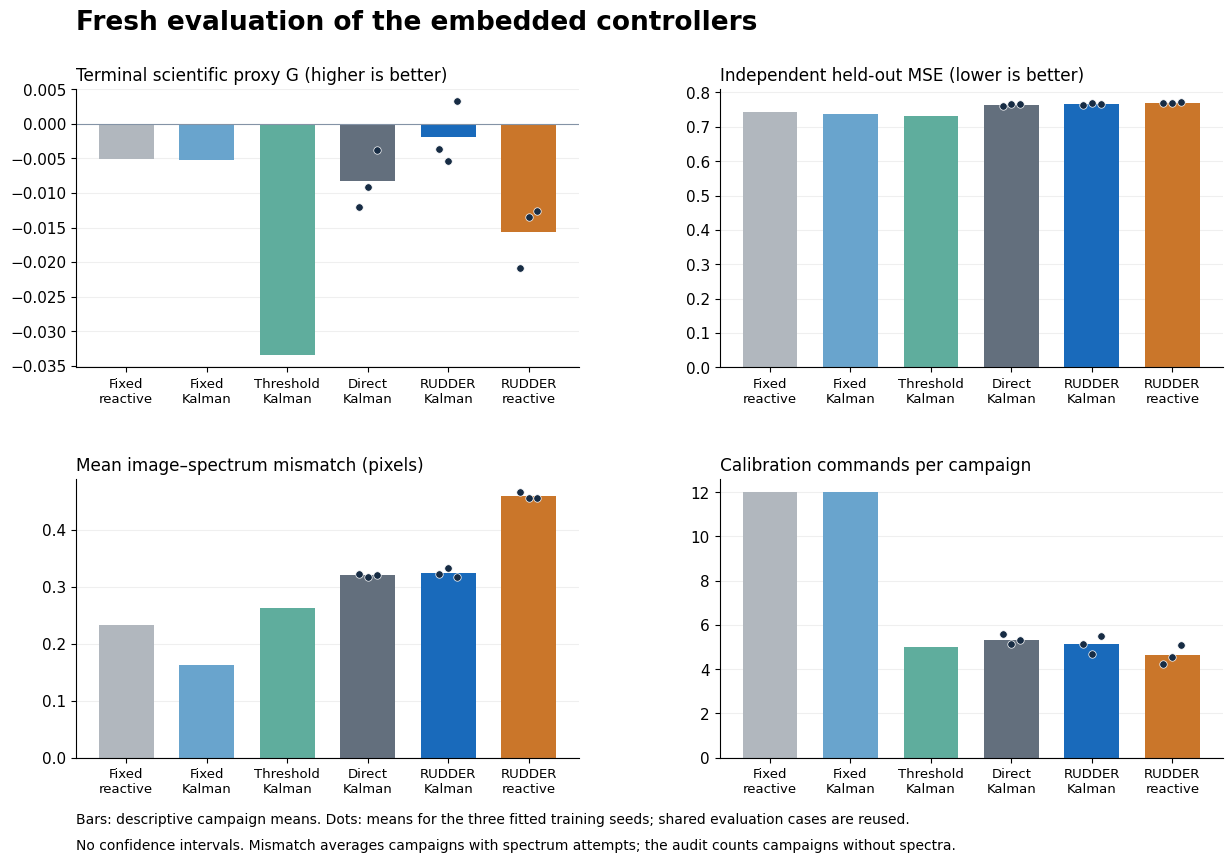

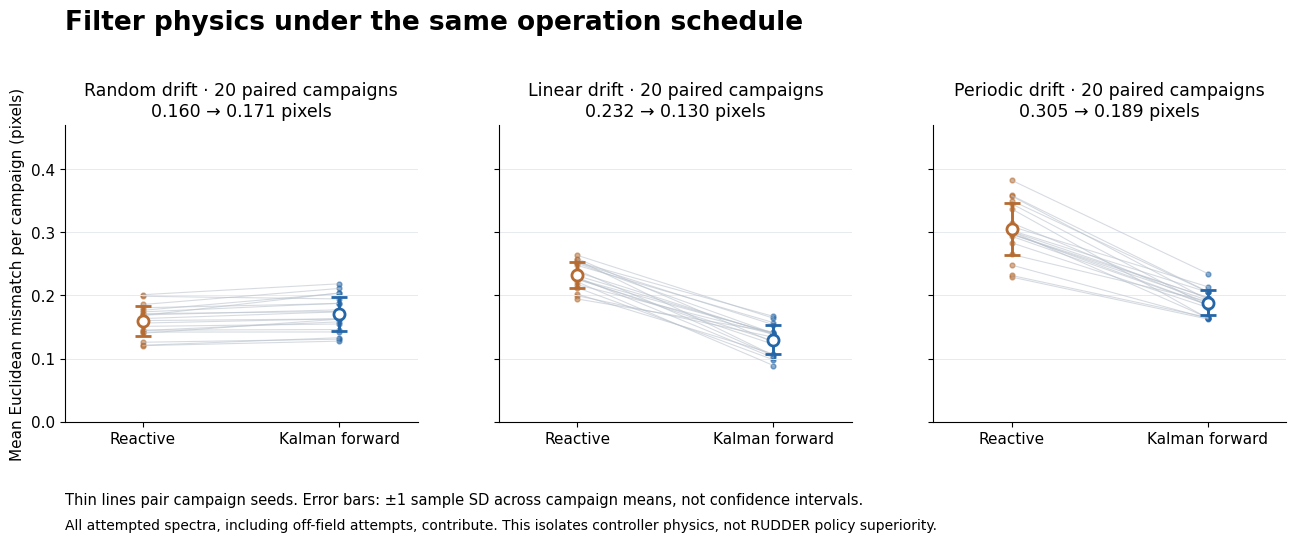

In [11]:
#@title Execute the 720-campaign evaluation and generate results
evaluation_seeds = list(range(EVALUATION_FIRST_SEED,
                              EVALUATION_FIRST_SEED + EVALUATION_SEEDS_PER_REGIME))
evaluation_start = time.perf_counter()
EVALUATION_ROWS, EVALUATION_EPISODES, EVALUATION_CHECKS = run_inline_evaluation(
    MODELS, DATA, ENVIRONMENT_CONFIG, evaluation_seeds)
print("Evaluation seconds:",round(time.perf_counter()-evaluation_start,2))
display(pd.Series(EVALUATION_CHECKS, name="Evaluation checks"))
SUMMARY = EVALUATION_ROWS.groupby("condition").mean(numeric_only=True)
display(SUMMARY[["terminal_score","heldout_mse","mean_pair_mismatch",
                 "n_calibrations","n_successful_pairs"]].round(6))
evaluation_figures = plot_inline_results(EVALUATION_ROWS, EVALUATION_EPISODES)
for figure in evaluation_figures.values():
    display(figure)
    plt.close(figure)


### Interpretation and covariance audit

Physical positioning error, scientific test MSE and the forest-disagreement reward can disagree. The pilot did not establish that learned RUDDER policies outperform simple workflows on scientific prediction. Compare each drift regime separately: a constant-velocity filter can help predictable drift and hurt random drift.

Forecast RMS must be calculated as sqrt(mean squared vector error), while predicted RMS is sqrt(mean covariance trace). These differ from mean Euclidean distance. Likewise, a pooled coverage near 95% can hide conservative linear estimates and overconfident periodic predictions. The next table is recomputed from the current evaluation traces, including every attempted spectrum.

In [12]:
#@title Recompute forecast RMS and coverage by condition and drift regime
REGISTRATION_AUDIT = inline_registration_audit(EVALUATION_EPISODES)
display(REGISTRATION_AUDIT.round(6))


,condition,regime,campaign_evaluations,distinct_campaign_seed_regime,campaigns_without_spectra,spectrum_attempts,mean_physical_pair_error_px,rms_physical_pair_error_px,actual_kf_forecast_rms_px,predicted_kf_rms_px,predicted_over_actual_rms_ratio,ellipse95_coverage,degenerate_support_failures
0,fixed_reactive,random,20,20,0,260,0.159834,0.180862,0.193182,0.239365,1.239064,0.988462,0
1,fixed_reactive,linear,20,20,0,260,0.232249,0.251871,0.148470,0.239365,1.612216,0.996154,0
2,fixed_reactive,periodic,20,20,0,260,0.305253,0.347625,0.207372,0.239365,1.154280,0.996154,0
3,fixed_reactive,ALL,60,60,0,780,0.232445,0.268944,0.184721,0.239365,1.295819,0.993590,0
4,fixed_kalman,random,20,20,0,260,0.170730,0.193182,0.193182,0.239365,1.239064,0.988462,0
5,fixed_kalman,linear,20,20,0,260,0.129797,0.148470,0.148470,0.239365,1.612216,0.996154,0
6,fixed_kalman,periodic,20,20,0,260,0.188886,0.207372,0.207372,0.239365,1.154280,0.996154,0
7,fixed_kalman,ALL,60,60,0,780,0.163138,0.184721,0.184721,0.239365,1.295819,0.993590,0
8,threshold_kalman,random,20,20,0,300,0.249688,0.288667,0.288667,0.397790,1.378025,0.996667,0
9,threshold_kalman,linear,20,20,0,300,0.110885,0.129937,0.129937,0.397790,3.061416,0.996667,0


## 8. Proposed next study

| Setting | Completed pilot | Suggested next study |
|---|---:|---:|
| Warmup campaigns per seed/correction mode | 64 | 256 |
| Policy-training campaigns per fitted model | 384 | 2,048 |
| Campaigns per policy update | 8 | 16 |
| Policy updates per model | 48 | 128 |
| Training seeds | 3 | 5 |
| Held-out test seeds per drift regime/model | 20 | 100 |

Keep budget 100, 12 seed pairs, eight tau settings from 0.2 to 1, image durations 3 × tau, CAL duration 1 and SPEC duration 1 for the controlled first comparison. Preserve the original drift speed 0.4 pixels/time, random-walk scale 0.16 pixels per unit knot, and periodic component amplitude 3 pixels/period 48. The periodic world also contains the linear trend.

The initial filter values are assumptions: registration SD 0.10 pixels, position diffusion 0.0256, acceleration density 0.0025 and initial velocity SD 0.40. Tune them on a separate validation set using innovations, forecast error and coverage per drift regime and action schedule. Suggested sweeps are registration SD 0.05/0.10/0.25 and process densities at one-quarter, nominal and four times their initial values. Do not tune using the final test outcomes.

The proposed 2,048 campaigns is a practical next budget, not a convergence guarantee. Extend to 4,096 only if independent validation learning curves are still improving. Check that the scientific objective reflects the intended learning quality before scaling training.

For a separate cost-generalization experiment, enable fresh training and cost randomization. Image factors are sampled in [2,4], calibration durations in [0.5,2], and spectrum durations in [0.5,2], with actual costs exposed to both networks. The filter propagates through actual durations. Test held-out fixed cost tables and extrapolation separately; the embedded fixed-cost pilot has not demonstrated cost transfer.

## Scope and references

- Registration is a simulated Gaussian sensor, with noise held independent of image blur and texture in this first comparison. It is not an image-registration algorithm validated on experimental image pairs.
- Acquisition uses midpoint representations, not integrated drift smearing. Actuator latency and saturation are absent. Time is in simulation units, not calibrated seconds.
- Images may use reflected boundary padding; an out-of-field spectrum costs time but returns no pair. In-field spectra use the nearest eligible measured pixel.
- The objective is mean forest disagreement reduction, not a calibrated posterior or guaranteed scientific accuracy. Physical truth and hidden test labels appear only in audit outputs.
- All code, data and fitted parameters needed for this notebook are contained above. The companion ZIP is optional and is never read by this notebook.

Primary references: [RUDDER, NeurIPS 2019](https://proceedings.neurips.cc/paper_files/paper/2019/file/16105fb9cc614fc29e1bda00dab60d41-Paper.pdf); [Welch & Bishop, Kalman filtering](https://www.cs.utexas.edu/~pstone/Courses/395Tfall05/readings/Welch%2BBishop-TR-95.pdf); [Särkkä, Bayesian filtering](https://users.aalto.fi/~ssarkka/course_k2011/pdf/handout3.pdf). [Colab FAQ](https://research.google.com/colaboratory/faq.html) describes uploading `.ipynb` files and hosted runtime behavior.